# Hodgkin-Huxley Neuron Model

The aim of this project is to implement a single Hodgkin-Huxley neuron and then perform a series of experiments related to gating kinetics and spiking.

In [1]:
# importing all the libraries necessary for modelling and visualization
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, Tuple
import math
from tqdm import tqdm
import ipywidgets as widgets
from dataclasses import dataclass, replace
from pathlib import Path

In [2]:
%config InlineBackend.figure_format = 'retina' # makes the plots better quality
np.random.seed(0) # this ensures that everything can be reproduced

## SETUP

We start by defining all the biophysical constants of the Hodgkin-Huxley neuron, all done inside a dataclass for ease of use.

The values assigned are the standard ones for a squid-axon.

In [3]:
@dataclass
class HHParams:
    Cm: float = 1.0          # µF/cm^2 (membrane capacitance)
    gNa: float = 120.0       # mS/cm^2 (max Na conductance)
    gK: float  = 36.0        # mS/cm^2 (max K conductance)
    gL: float  = 0.3         # mS/cm^2 (leak conductance)

    ENa: float = 50.0        # mV (Na reversal)
    EK:  float = -77.0       # mV (K reversal)
    EL:  float = -54.387     # mV (leak reversal)

    # for temperature scaling
    use_Q10: bool = False
    Q10: float = 3.0         # typical for gating kinetics
    T_ref: float = 6.3       # °C reference
    T_exp: float = 6.3       # °C experiment

params = HHParams()

Where the membrane capacitance is calculated according to:
$$
C_m \frac{dV}{dt}
= I_{\mathrm{ext}}(t)
- \Bigl[
I_{\mathrm{Na}}
+ I_{\mathrm{K}}
+ I_{\mathrm{L}}
\Bigr]
$$
And the 3 terms within the parentheses are the ionic currents, given by:
\
\begin{aligned}
I_{\mathrm{Na}} &= \bar g_{\mathrm{Na}}\, m^{3} h \,(V - E_{\mathrm{Na}})\\
I_{\mathrm{K}}  &= \bar g_{\mathrm{K}}\, n^{4}\,(V - E_{\mathrm{K}})\\
I_{\mathrm{L}}  &= g_{\mathrm{L}}\, (V - E_{\mathrm{L}})
\end{aligned}

The HH neuron is a single-compartment electrical circuit: the membrane behaves like a capacitor \(Cm\) in parallel with three variable conductances — voltage‑gated sodium $g_{\mathrm{Na}} m^3 h$, voltage‑gated potassium $g_{\mathrm{K}} n^4$, and a passive leak $g_{\mathrm{L}}$ — each with its own reversal potential $(E_{\mathrm{Na}}, E_{\mathrm{K}}, E_{\mathrm{L}})$.

Sodium activation \(m\) opens quickly and drives the upstroke of the action potential; sodium inactivation \(h\) closes more slowly to terminate Na influx; potassium activation \(n\) opens with a delay to repolarize the cell.

External current injection $I_{\mathrm{ext}}(t)$ depolarizes the cell; if the Na activation overcomes K+ and leak, a spike is generated.


Next, we define a few helper functions in order to avoid running into errors later.

In [4]:
def _arr(x): # makes sure all inputs are numpy arrays
    return np.asarray(x, dtype=float)

def _lim_ratio(x, k, limit): # evaluates the limit near 0, avoids errors
# we need this because of the equations for the gating variables, since division by 0 is impossible
    x = np.asarray(x, dtype=float)
    y = x / k
    mask = np.abs(y) < 1e-6
    out = np.full_like(y, float(limit))
    den = -np.expm1(-y)
    out[~mask] = x[~mask] / den[~mask]
    return out

def _q10_factor(p: HHParams): # temperature scaling
    if not p.use_Q10:
        return 1.0
    # scale gating rates by Q10^((T_exp - T_ref)/10)
    return p.Q10 ** ((p.T_exp - p.T_ref) / 10.0)

Then we define the activation and inactivation gating variables, which are calculated and then converted into relaxed state.

In [5]:
def alpha_m(V, p=params):
    V = _arr(V)
    return 0.1 * _lim_ratio(V + 40.0, 10.0, 10.0) * _q10_factor(p)

def beta_m(V, p=params):
    V = _arr(V)
    return 4.0 * np.exp(-(V + 65.0) / 18.0) * _q10_factor(p)

def alpha_h(V, p=params):
    V = _arr(V)
    return 0.07 * np.exp(-(V + 65.0) / 20.0) * _q10_factor(p)

def beta_h(V, p=params):
    V = _arr(V)
    return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0)) * _q10_factor(p)

def alpha_n(V, p=params):
    V = _arr(V)
    return 0.01 * _lim_ratio(V + 55.0, 10.0, 10.0) * _q10_factor(p)

def beta_n(V, p=params):
    V = _arr(V)
    return 0.125 * np.exp(-(V + 65.0) / 80.0) * _q10_factor(p)

def gate_inf_tau(V, p=params):
    """
    Return dictionaries:
      x_inf: dict with m,h,n steady-state values at voltage V
      tau_x: dict with m,h,n time-constants (ms) at voltage V
    """
    am, bm = alpha_m(V, p), beta_m(V, p)
    ah, bh = alpha_h(V, p), beta_h(V, p)
    an, bn = alpha_n(V, p), beta_n(V, p)

    m_tau = 1.0 / (am + bm)
    h_tau = 1.0 / (ah + bh)
    n_tau = 1.0 / (an + bn)

    m_inf = am * m_tau
    h_inf = ah * h_tau
    n_inf = an * n_tau

    return {"m": m_inf, "h": h_inf, "n": n_inf}, {"m": m_tau, "h": h_tau, "n": n_tau}


Where the gating variables are calculated according to first-order kinetics:
$$
\frac{dx}{dt}
= \alpha_x(V)\,(1 - x) - \beta_x(V)\,x
\qquad x \in \{m,h,n\}
$$

Which can be rewritten as:
$$
\frac{dx}{dt}
= \frac{x_\infty(V) - x}{\tau_x(V)}
$$

Where the steady state and time constant are equal to:
$$
x_\infty(V) = \frac{\alpha_x(V)}{\alpha_x(V) + \beta_x(V)}
\qquad
\tau_x(V) = \frac{1}{\alpha_x(V) + \beta_x(V)}
$$
Ultimately, we get these individual equations (for HH):
\
\begin{aligned}
\alpha_m(V) &= 0.1\,\frac{V+40}{1-\exp\!\big(-(V+40)/10\big)}
&\qquad
\beta_m(V)  &= 4\,\exp\!\big(-(V+65)/18\big),\\[4pt]
\alpha_h(V) &= 0.07\,\exp\!\big(-(V+65)/20\big)
&\qquad
\beta_h(V)  &= \frac{1}{1+\exp\!\big(-(V+35)/10\big)}\\[4pt]
\alpha_n(V) &= 0.01\,\frac{V+55}{1-\exp\!\big(-(V+55)/10\big)}
&\qquad
\beta_n(V)  &= 0.125\,\exp\!\big(-(V+65)/80\big)
\end{aligned}

In [6]:
# we check the gating variables at rest
V0 = -65.0
x_inf, tau_x = gate_inf_tau(V0, params)
print("At V = -65 mV")
for k in ("m","h","n"):
    print(f"{k}_inf = {x_inf[k]:.6f}, tau_{k} = {tau_x[k]:.3f} ms")

At V = -65 mV
m_inf = 0.052932, tau_m = 0.237 ms
h_inf = 0.596121, tau_h = 8.516 ms
n_inf = 0.317677, tau_n = 5.459 ms


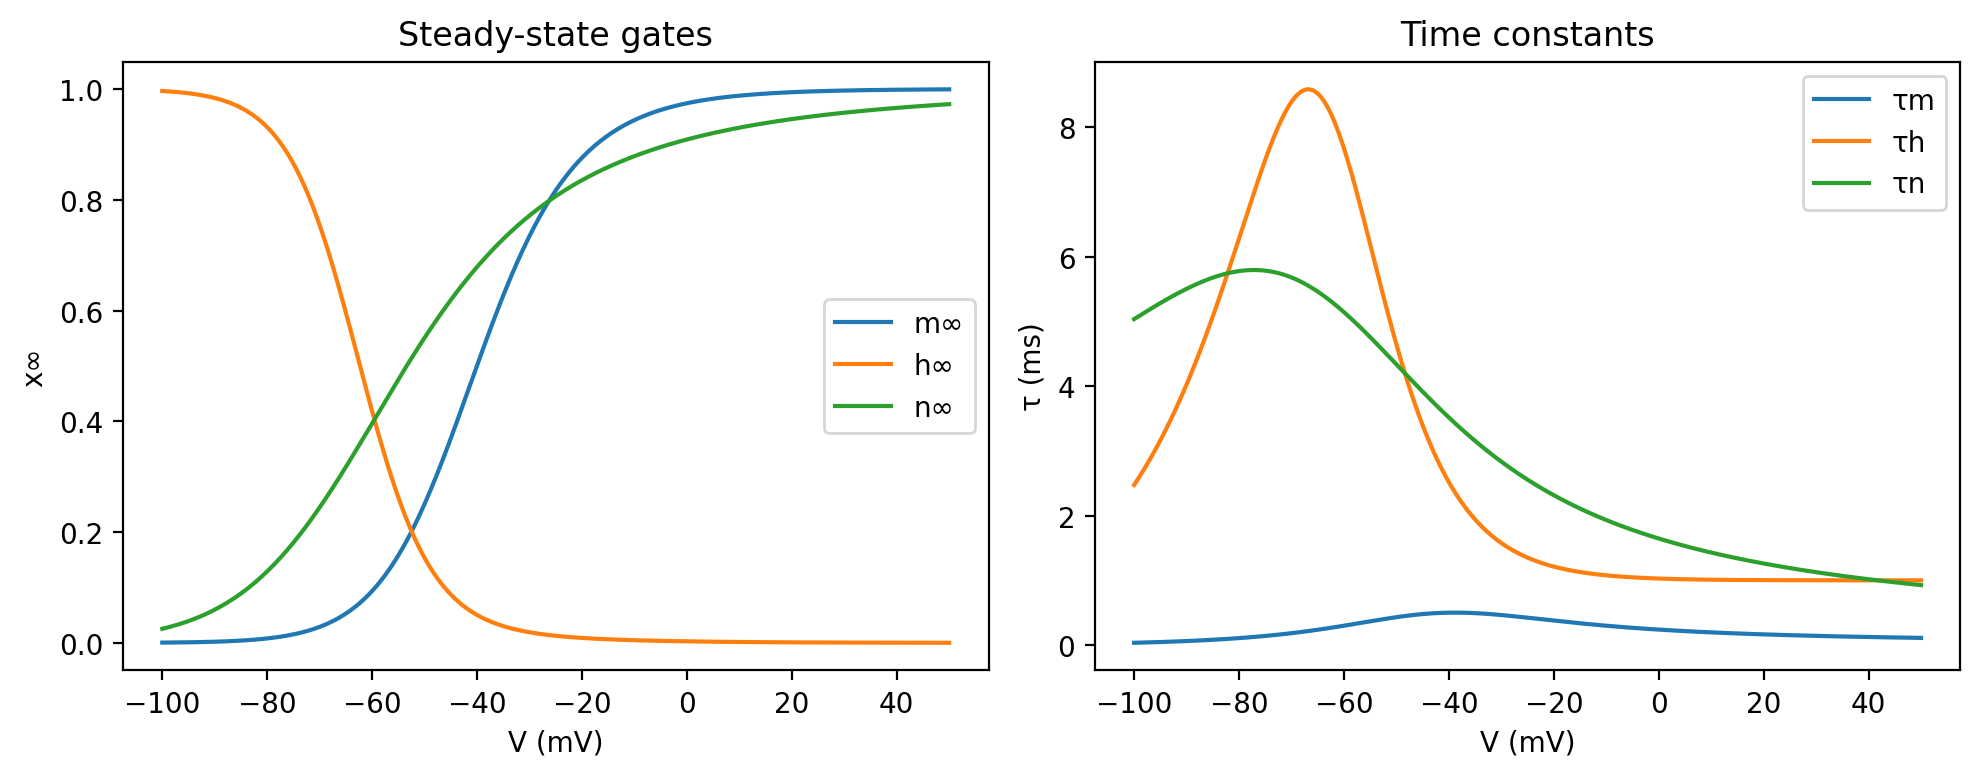

In [7]:
Vs = np.linspace(-100, 50, 400)
x_inf, tau_x = gate_inf_tau(Vs, params)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(Vs, x_inf["m"], label="m∞")
axes[0].plot(Vs, x_inf["h"], label="h∞")
axes[0].plot(Vs, x_inf["n"], label="n∞")
axes[0].set_xlabel("V (mV)"); axes[0].set_ylabel("x∞"); axes[0].set_title("Steady-state gates")
axes[0].legend()

axes[1].plot(Vs, tau_x["m"], label="τm")
axes[1].plot(Vs, tau_x["h"], label="τh")
axes[1].plot(Vs, tau_x["n"], label="τn")
axes[1].set_xlabel("V (mV)"); axes[1].set_ylabel("τ (ms)"); axes[1].set_title("Time constants")
axes[1].legend()
plt.tight_layout()
plt.show()

- $m_{\infty}$ increases with $V$ and $\tau_m$ is small $\Rightarrow$ fast $\mathrm{Na}^+$ activation (drives the upstroke).
- $h_{\infty}$ decreases with $V$ and $\tau_h$ is larger $\Rightarrow$ $\mathrm{Na}^+$ inactivation turns the $\mathrm{Na}^+$ current off.
- $n_{\infty}$ increases with $V$ and $\tau_n$ is intermediate $\Rightarrow$ delayed $\mathrm{K}^+$ activation repolarizes and produces AHP.


Then we define the ionic currents and the stimuli, which we will need when we run the experiments.

In [8]:
def ionic_currents(V, m, h, n, p=params): # defined according to the equations seen above
    gNa = p.gNa * (m**3) * h
    gK  = p.gK  * (n**4)
    gL  = p.gL
    INa = gNa * (V - p.ENa)
    IK  = gK  * (V - p.EK)
    IL  = gL  * (V - p.EL)
    return INa, IK, IL

# stimuli
def step_pulse(t, amp=10.0, t_on=10.0, t_off=11.0): # short square pulse
    return amp if (t_on <= t < t_off) else 0.0

def long_step_current(t, amp=10.0, t_on=10.0, t_off=110.0): # long square step
    return amp if (t_on <= t < t_off) else 0.0

def ramp_current(t, t_on=10.0, t_off=110.0, I0=0.0, I1=12.0): # ramps from I0 to I1 linearly
    if t < t_on: return 0.0
    if t <= t_off: return I0 + (I1 - I0) * ((t - t_on) / (t_off - t_on))
    return I1

So far we're working in a continuous-time ODE model, however we need discrete times for our purposes, thus we use the forward Euler method to turn each ODE into an update rule that can simulate V, m, n, h at discrete times.
The Euler discretization (using first order Taylor expansion) is:
$$
\begin{aligned}
V_{k+1}
&= V_k \;+\; \Delta t \;\frac{ I_{\mathrm{ext}}(t_k) \;-\; \big( I_{\mathrm{Na}} + I_{\mathrm{K}} + I_{\mathrm{L}} \big)_k }{ C_m }\\[6pt]
x_{k+1}
&= x_k \;+\; \Delta t \;\frac{ x_{\infty}(V_k) \;-\; x_k }{ \tau_x(V_k) }
\end{aligned}
$$


In [9]:
def simulate_hh(T=50.0, dt=0.01, V0=-65.0, I_of_t=step_pulse, p=params): # time steps of 0.01
    steps = int(np.round(T / dt)) + 1
    t  = np.arange(steps) * dt

    V = np.empty(steps); m = np.empty(steps); h = np.empty(steps); n = np.empty(steps)
    x_inf0, _ = gate_inf_tau(V0, p)
    V[0] = V0; m[0] = float(x_inf0["m"]); h[0] = float(x_inf0["h"]); n[0] = float(x_inf0["n"])

    INa_arr = np.empty(steps); IK_arr = np.empty(steps); IL_arr = np.empty(steps)

    for k in range(steps - 1):
        Iext = I_of_t(t[k])

        x_inf, tau_x = gate_inf_tau(V[k], p)
        dmdt = (x_inf["m"] - m[k]) / tau_x["m"]
        dhdt = (x_inf["h"] - h[k]) / tau_x["h"]
        dndt = (x_inf["n"] - n[k]) / tau_x["n"]

        INa, IK, IL = ionic_currents(V[k], m[k], h[k], n[k], p)
        dVdt = (Iext - (INa + IK + IL)) / p.Cm

        V[k+1] = V[k] + dt * dVdt
        m[k+1] = np.clip(m[k] + dt * dmdt, 0.0, 1.0)
        h[k+1] = np.clip(h[k] + dt * dhdt, 0.0, 1.0)
        n[k+1] = np.clip(n[k] + dt * dndt, 0.0, 1.0)

        INa_arr[k], IK_arr[k], IL_arr[k] = INa, IK, IL

    INa_arr[-1], IK_arr[-1], IL_arr[-1] = ionic_currents(V[-1], m[-1], h[-1], n[-1], p)
    return {"t": t, "V": V, "m": m, "h": h, "n": n, "INa": INa_arr, "IK": IK_arr, "IL": IL_arr}

## EXPERIMENTS

Now we can begin running our experiments and plotting them out.

### Current clamp

We begin with current-clamp experiments (single pulse, long step, slow ramp).

In the first experiment, we test whether a short depolarizing pulse can elicit an action potential and how spike probability depends on pulse amplitude and duration. This probes the strength–duration trade-off and shows that gating variables need sufficient time to open/close (membrane & channel kinetics), not just large amplitude.

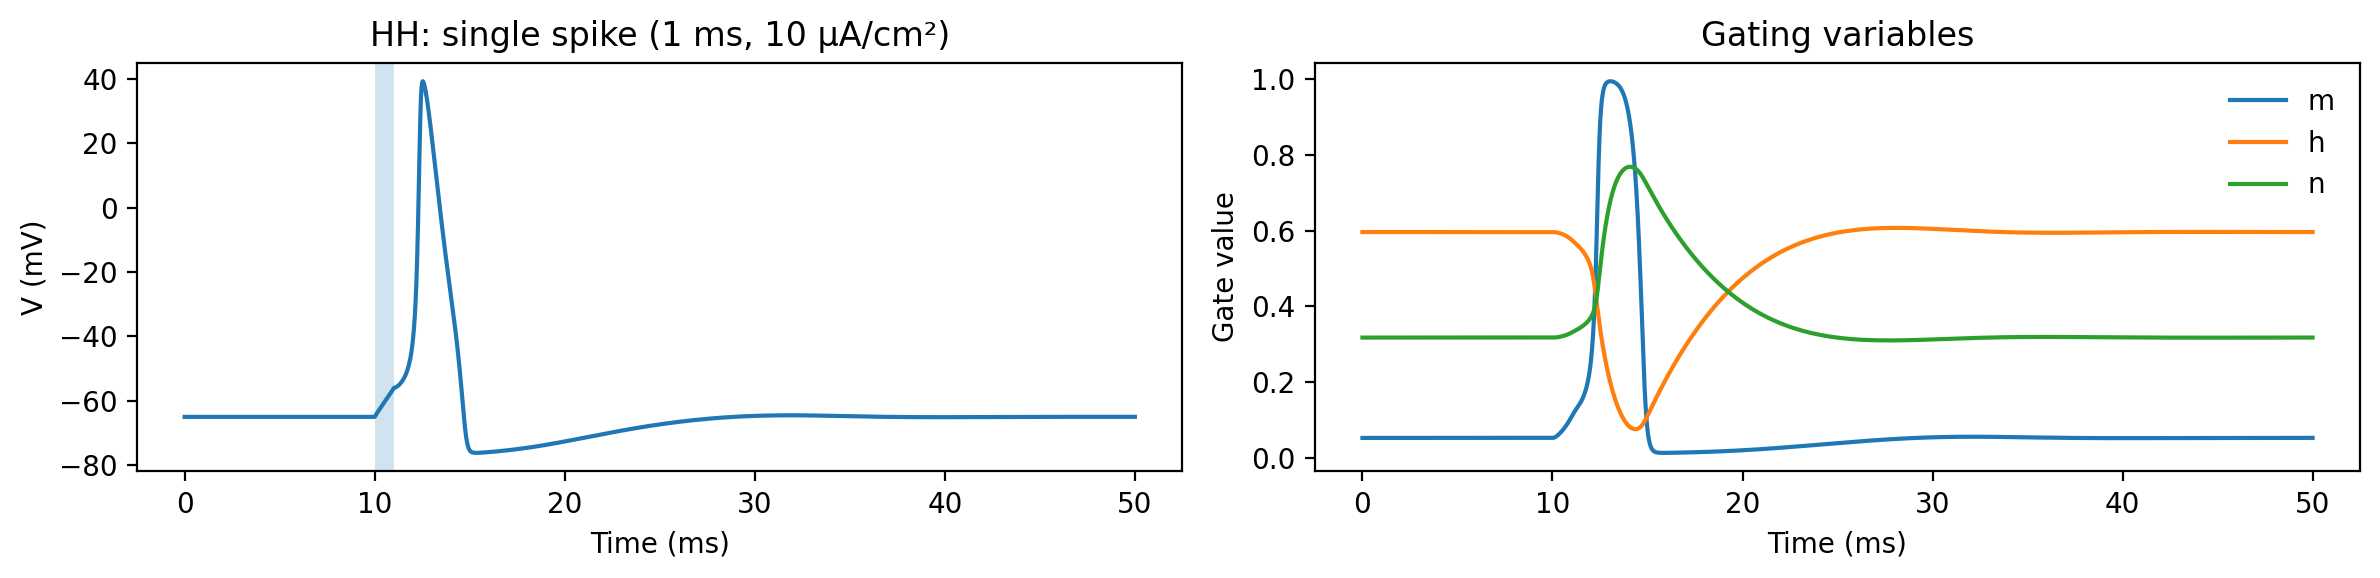

In [10]:
# single brief pulse → single spike
res = simulate_hh(T=50.0, dt=0.01, V0=-65.0,
                  I_of_t=lambda t: step_pulse(t, amp=10.0, t_on=10.0, t_off=11.0),
                  p=params)
t, V, m, h, n = res["t"], res["V"], res["m"], res["h"], res["n"]

# to show the plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharex=False)

# membrane potential on the left
axes[0].plot(t, V)
axes[0].axvspan(10, 11, alpha=0.2)
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("V (mV)")
axes[0].set_title("HH: single spike (1 ms, 10 µA/cm²)")

# gating variables on the right
axes[1].plot(t, m, label="m")
axes[1].plot(t, h, label="h")
axes[1].plot(t, n, label="n")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Gate value")
axes[1].set_title("Gating variables")
axes[1].legend(loc="best", frameon=False)

plt.tight_layout()
plt.show()

A brief, sufficiently strong pulse kicks off Na-driven positive feedback (m↑) to generate one AP; concurrent Na inactivation (h↓) and delayed K activation (n↑) terminate the spike and create the undershoot. Because the pulse is short and 𝑛 remains elevated while ℎ is depressed, the membrane is less excitable right after the spike, so you get exactly one spike.

The next two experiments consist of a long step and slow ramping.

For the long step, we probe steady firing under a sustained depolarization to characterize excitability and basic timing (ISI / rate).

For the ramp, we test the threshold accommodations (i.e.: whether a slowly rising input raises the effective threshold compared to a step)

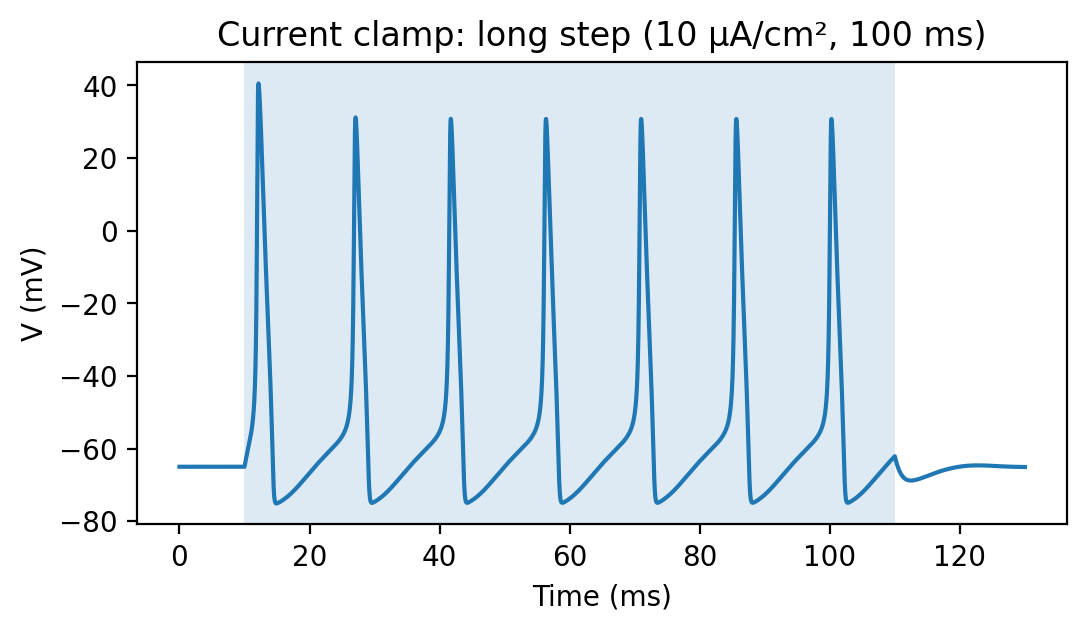

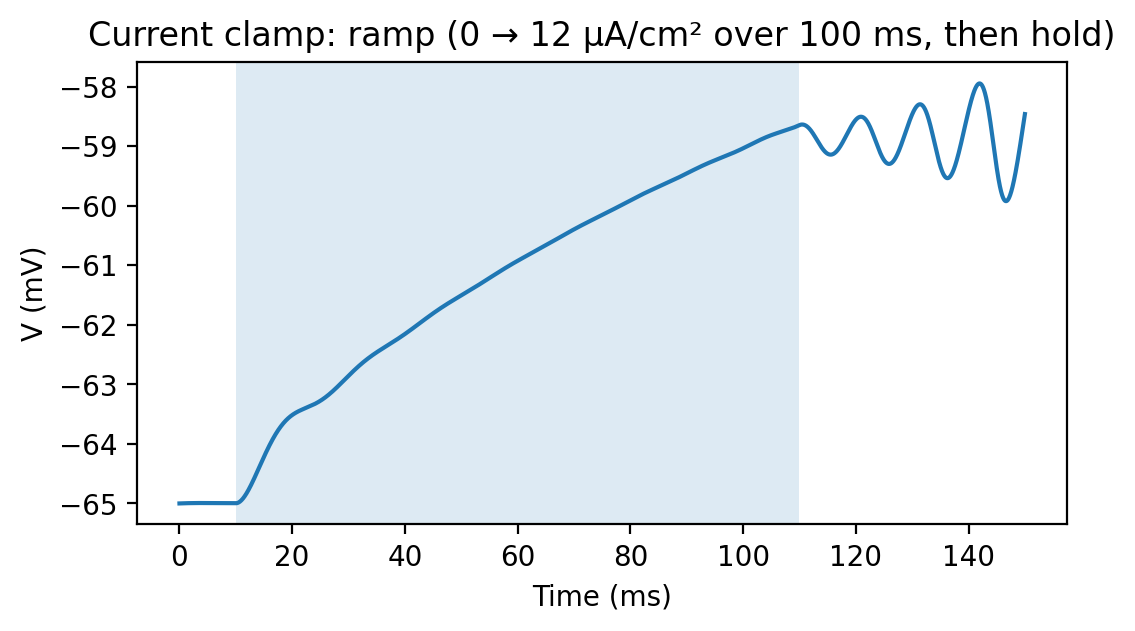

In [11]:
# long step → tonic spiking
res_step = simulate_hh(T=130.0, dt=0.01, V0=-65.0,
                       I_of_t=lambda t: long_step_current(t, amp=10.0, t_on=10.0, t_off=110.0),
                       p=params)

plt.figure(figsize=(6,3))
plt.plot(res_step["t"], res_step["V"]); plt.axvspan(10, 110, alpha=0.15)
plt.xlabel("Time (ms)"); plt.ylabel("V (mV)")
plt.title("Current clamp: long step (10 µA/cm², 100 ms)")
plt.show()

# ramp → threshold crossing and spiking
res_ramp = simulate_hh(T=150.0, dt=0.01, V0=-65.0,
                       I_of_t=lambda t: ramp_current(t, t_on=10.0, t_off=110.0, I0=0.0, I1=12.0),
                       p=params)

plt.figure(figsize=(6,3))
plt.plot(res_ramp["t"], res_ramp["V"]); plt.axvspan(10, 110, alpha=0.15)
plt.xlabel("Time (ms)"); plt.ylabel("V (mV)")
plt.title("Current clamp: ramp (0 → 12 µA/cm² over 100 ms, then hold)")
plt.show()


Long step: a sustained positive current shifts the balance toward inward Na current enough to cross threshold on each cycle; delayed K activation repolarizes and sets the inter-spike interval. With these classic HH parameters the cell shows tonic spiking for this input level.

Ramp: with a slow ramp, K activation (n) rises and Na inactivation (h) falls while the voltage creeps up. This pre-conditions the membrane into a less excitable state, so the neuron fails to spike even though the final current (12 µA/cm²) is higher than the step case that produced robust spiking at 10 µA/cm². That’s classic accommodation. If the ramp were faster (or the hold were longer to let ℎ recover / 𝑛 relax), a spike would likely appear at a lower effective current.

We quantify the pulse, step, and ramp results: for the 1-ms pulse we report baseline
𝑉, peak, amplitude, half-width, and AHP depth; for the 100-ms step we compute steady firing rate and ISI statistics; for the ramp we estimate the current at the first spike.

Spike times use upward threshold crossings with a 2-ms refractory and linear interpolation.

In [12]:
def detect_spikes(t, V, thresh=0.0, refractory=2.0):
  # its real use is in the next section of experiments, but it is also needed for the metrics
  # so we introduce it here
  # returns an array of spike times
    t = np.asarray(t); V = np.asarray(V)
    above = V > thresh
    idx = np.where((~above[:-1]) & (above[1:]))[0] + 1
    spike_times = []
    last = -1e9
    for i in idx:
        t0, t1 = t[i-1], t[i]
        v0, v1 = V[i-1], V[i]
        # linear interpolation for better timing
        tc = t1 if v1 == v0 else t0 + (thresh - v0) * (t1 - t0) / (v1 - v0)
        if tc - last >= refractory:
            spike_times.append(tc); last = tc
    return np.array(spike_times, float)

In [13]:
def half_width(t, V, t_peak_idx, V_baseline):
    Vpk = V[t_peak_idx]
    half = V_baseline + 0.5*(Vpk - V_baseline)
    # find first crossing before peak
    i_up = np.where((V[:-1] < half) & (V[1:] >= half) & (np.arange(len(V)-1) < t_peak_idx))[0]
    # find first crossing after peak
    i_dn = np.where((V[:-1] >= half) & (V[1:] < half) & (np.arange(len(V)-1) > t_peak_idx))[0]
    if i_up.size == 0 or i_dn.size == 0:
        return np.nan
    # linear interpolation
    iu = i_up[-1]
    idn = i_dn[0]
    t_up = t[iu] + (half - V[iu])*(t[iu+1]-t[iu])/(V[iu+1]-V[iu] + 1e-12)
    t_dn = t[idn] + (half - V[idn])*(t[idn+1]-t[idn])/(V[idn+1]-V[idn] + 1e-12)
    return t_dn - t_up

# brief pulse metrics (1 ms @ 10 µA/cm² at 10 ms) ---
stim_pulse = lambda t: (10.0 if (10.0 <= t < 11.0) else 0.0)
res_p = simulate_hh(T=50.0, dt=0.01, V0=-65.0, I_of_t=stim_pulse, p=params)
t, V = res_p["t"], res_p["V"]

# baseline from a pre-pulse window
pre = (t >= 5.0) & (t < 10.0)
V_base = float(np.mean(V[pre]))
i_peak = int(np.argmax(V))
V_peak = float(V[i_peak])
amp = V_peak - V_base
w_half = half_width(t, V, i_peak, V_base)

# AHP min after peak (search up to 30 ms after peak or end)
post_mask = (t >= t[i_peak]) & (t <= min(t[-1], t[i_peak]+30.0))
V_ahp = float(np.min(V[post_mask])) if np.any(post_mask) else np.nan
AHP_depth = V_base - V_ahp  # positive value means below baseline

print("=== Brief pulse metrics ===")
print(f"Baseline V: {V_base:.2f} mV")
print(f"Peak V:     {V_peak:.2f} mV  (Amplitude: {amp:.2f} mV)")
print(f"AP half-width: {w_half:.3f} ms")
print(f"AHP minimum:  {V_ahp:.2f} mV  (Depth: {AHP_depth:.2f} mV)")

# long step metrics (100 ms @ 10 µA/cm² from 10 to 110 ms) ---
stim_step = lambda t: (10.0 if (10.0 <= t < 110.0) else 0.0)
res_s = simulate_hh(T=140.0, dt=0.01, V0=-65.0, I_of_t=stim_step, p=params)
ts, Vs = res_s["t"], res_s["V"]
spk = detect_spikes(ts, Vs, thresh=0.0, refractory=2.0)

# count spikes in steady window (discard first 30 ms after onset)
steady = spk[(spk >= 40.0) & (spk <= 110.0)]
rate = len(steady) / ((110.0 - 40.0)/1000.0) if len(steady) > 1 else (len(steady) / ((110.0 - 40.0)/1000.0))
isis = np.diff(steady)
isi_mean = float(np.mean(isis)) if isis.size else np.nan
isi_cv = float(np.std(isis)/np.mean(isis)) if isis.size else np.nan

print("\n=== Long step metrics ===")
print(f"Spikes in 40–110 ms: {len(steady)}")
print(f"Steady firing rate:   {rate:.2f} Hz")
print(f"ISI mean:             {isi_mean:.3f} ms   (CV: {isi_cv:.3f})")

# ramp: first-spike current estimate (0→12 µA/cm² over 100 ms) ---
def ramp_I(t, t_on=10.0, t_off=110.0, I0=0.0, I1=12.0):
    if t < t_on: return 0.0
    if t <= t_off: return I0 + (I1 - I0) * ((t - t_on) / (t_off - t_on))
    return I1

res_r = simulate_hh(T=150.0, dt=0.01, V0=-65.0, I_of_t=ramp_I, p=params)
tr, Vr = res_r["t"], res_r["V"]
spk_r = detect_spikes(tr, Vr, thresh=0.0, refractory=2.0)
if spk_r.size:
    t1 = float(spk_r[0])
    # compute I at that time
    I_at_t1 = ramp_I(t1)
    print("\n=== Ramp metrics ===")
    print(f"First spike at t = {t1:.2f} ms  →  I ≈ {I_at_t1:.2f} µA/cm²")
else:
    print("\n=== Ramp metrics ===")
    print("No spike during ramp.")


=== Brief pulse metrics ===
Baseline V: -65.00 mV
Peak V:     39.33 mV  (Amplitude: 104.32 mV)
AP half-width: 1.443 ms
AHP minimum:  -76.19 mV  (Depth: 11.19 mV)

=== Long step metrics ===
Spikes in 40–110 ms: 5
Steady firing rate:   71.43 Hz
ISI mean:             14.632 ms   (CV: 0.000)

=== Ramp metrics ===
No spike during ramp.


Brief pulse: a 1-ms, 10 µA/cm² pulse evokes a single 104 mV AP (half-width 1.44 ms) with an 11 mV AHP; post-spike h↓ and n↑ prevent re-spiking.

Long step: a 10 µA/cm², 100-ms step produces regular tonic firing (~70 Hz; CV≈0), consistent with HH Type-II excitability; small rate/ISI discrepancies come from windowing.

Ramp: a slow 0→12 µA/cm² ramp yields no spikes—evidence of accommodation—so the effective threshold for this slope exceeds 12 µA/cm², higher than the step rheobase.

### Firing rate and DC current

The next experiment consists of measuring the steady firing rate vs DC current and estimating the rheobase.

First, we quantify how steady firing rate depends on injected current 𝐼. Then identify the rheobase (onset of sustained spiking) and the excitability type from the shape of the f–I curve.

We do so by detecting spikes by upward threshold crossings with a 2 ms refractory; counting the spikes in the steady window (last 600 ms of a 900 ms step). The we plot the f-I curve.


Estimated rheobase (≥1.67 Hz): 6.250 µA/cm²


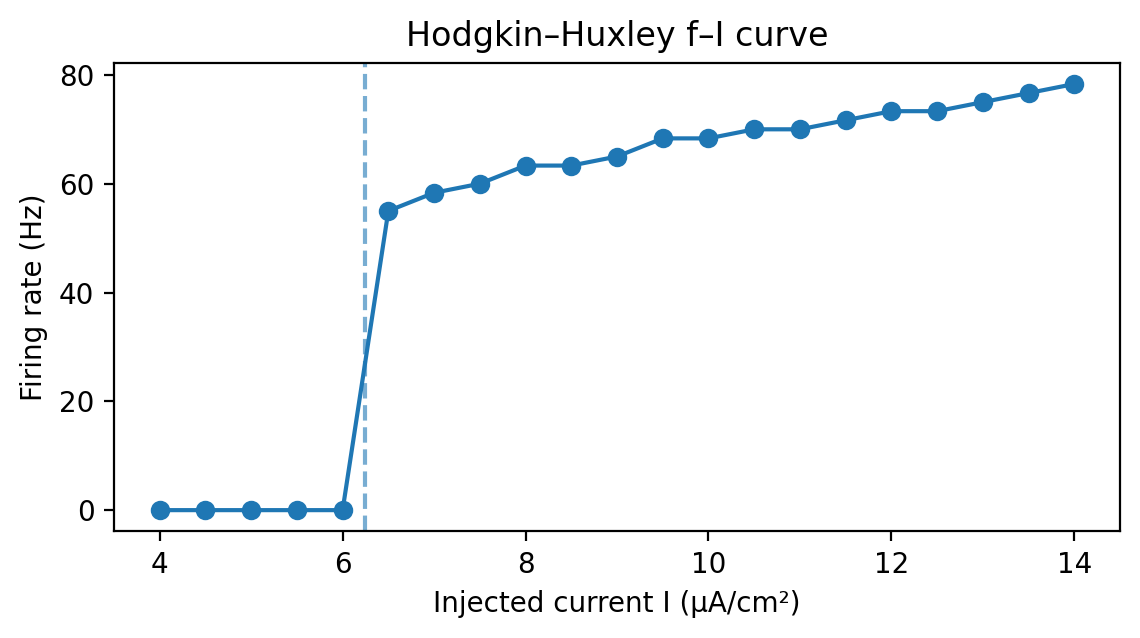

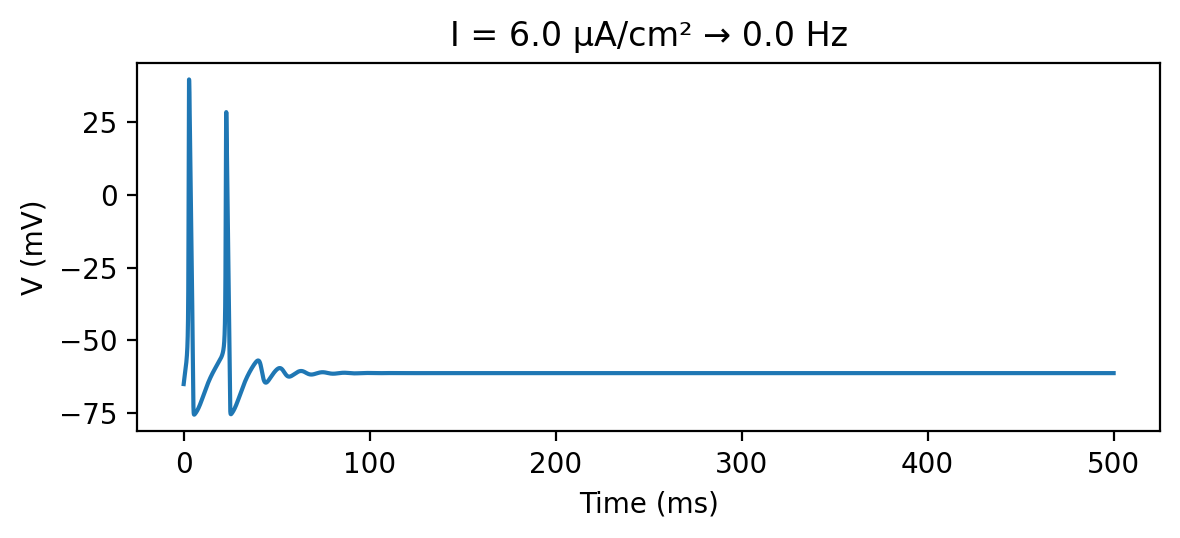

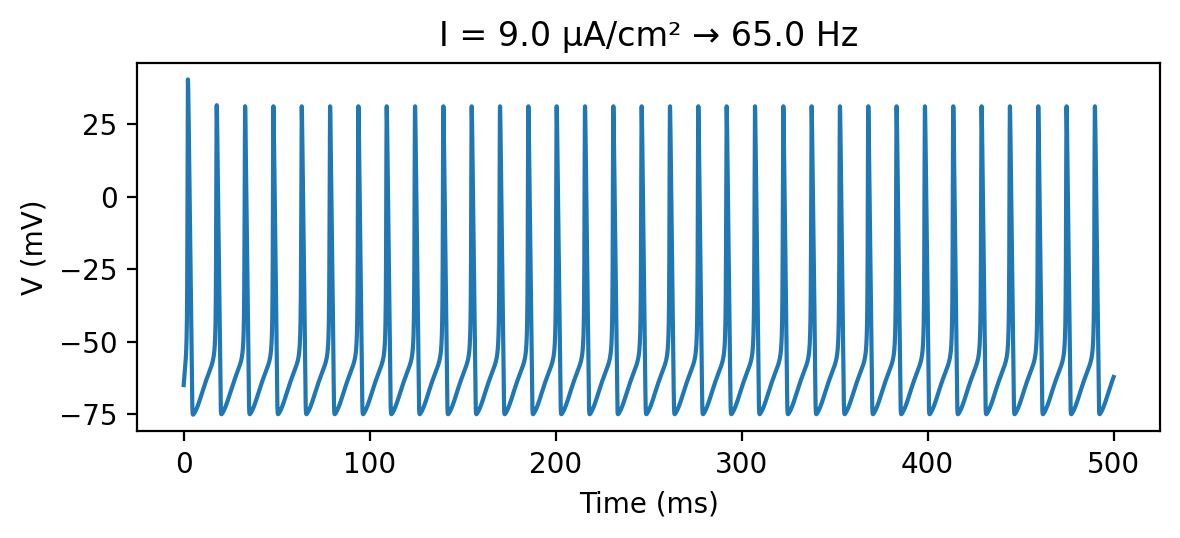

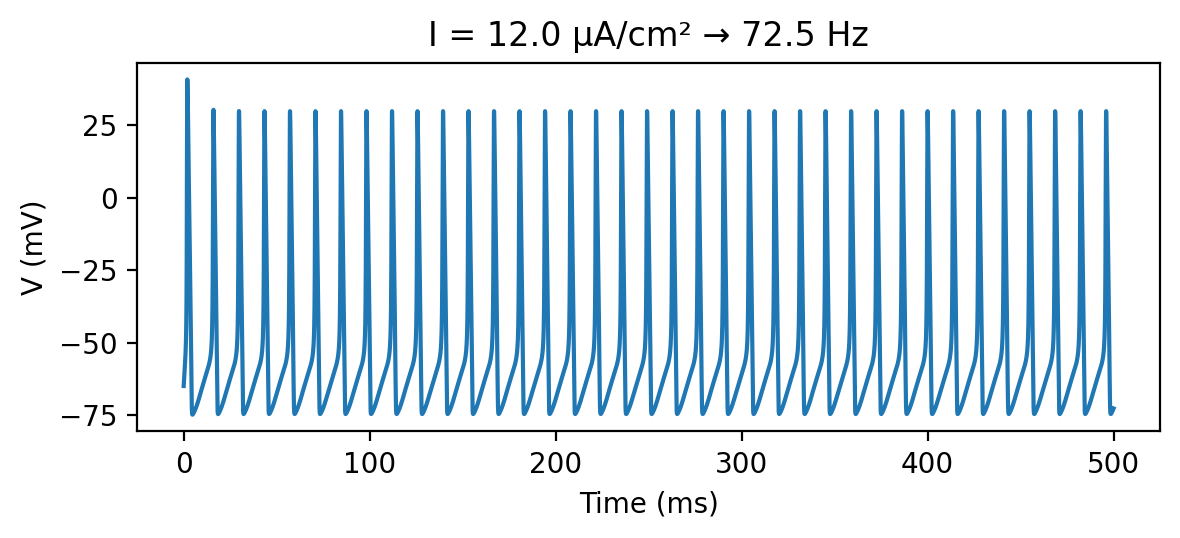

In [14]:
def run_constant_current(I, T=900.0, dt=0.01, V0=-65.0, warmup=300.0):
  # constant current is injected, returns (firing_rate, res, spk)
    res = simulate_hh(T=T, dt=dt, V0=V0, I_of_t=lambda t, I=I: I, p=params)
    spk = detect_spikes(res["t"], res["V"], thresh=0.0, refractory=2.0)
    keep = spk >= warmup
    n_spikes = int(np.sum(keep))
    dur_s = (T - warmup) / 1000.0
    fr = (n_spikes / dur_s) if dur_s > 0 else 0.0
    return fr, res, spk

# f-I curve (firing rate vs injected current)
I_values = np.linspace(4.0, 14.0, 21)  # µA/cm^2
firing_rates = []
for I in I_values:
    fr, _, _ = run_constant_current(I, T=900.0, dt=0.01, warmup=300.0)
    firing_rates.append(fr)
firing_rates = np.array(firing_rates)

# estimates rheobase (onset current for repetitive firing)
mask = firing_rates >= 1.67
if np.any(mask):
    i0 = int(np.argmax(mask))
    I_lo = I_values[max(i0-1, 0)]; I_hi = I_values[i0]
    I_fine = np.linspace(I_lo, I_hi, 15)
    FR_fine = []
    for I in I_fine:
        fr, _, _ = run_constant_current(I, T=900.0, dt=0.01, warmup=300.0)
        FR_fine.append(fr)
    FR_fine = np.array(FR_fine)
    j = int(np.argmax(FR_fine >= 1.0))
    rheobase = I_fine[j]
else:
    rheobase = np.nan

print(f"Estimated rheobase (≥1.67 Hz): {rheobase:.3f} µA/cm²")

# f-I plot
plt.figure(figsize=(5.8,3.3))
plt.plot(I_values, firing_rates, marker="o")
if np.isfinite(rheobase):
    plt.axvline(rheobase, ls="--", alpha=0.6)
plt.xlabel("Injected current I (µA/cm²)")
plt.ylabel("Firing rate (Hz)")
plt.title("Hodgkin–Huxley f–I curve")
plt.tight_layout(); plt.show()

# examples
for I in [6.0, 9.0, 12.0]:
    fr, res, spk = run_constant_current(I, T=500.0, dt=0.01, warmup=100.0)
    plt.figure(figsize=(6.0,2.8))
    plt.plot(res["t"], res["V"])
    plt.xlabel("Time (ms)"); plt.ylabel("V (mV)")
    plt.title(f"I = {I:.1f} µA/cm² → {fr:.1f} Hz")
    plt.tight_layout(); plt.show()


The finite-frequency onset confirms type II excitability for standard HH parameters: once the threshold is crossed, the system settles onto a limit cycle with non-zero frequency.

Rate increases moderately with current because stronger drive shortens the repolarization/charging phases each cycle; K activation still governs the ISI.

The 𝐼= 6.0 example illustrates how transient spikes can appear below rheobase but do not count toward sustained firing once the system relaxes.

### Refractory periods

We now move on to experiments with refractory periods and paired pulses.

We test how quickly the neuron can fire again after an action potential. Two identical depolarizing pulses are delivered with an onset-to-onset gap Δ. By determining whether a second spike occurs and how long it takes to appear, we quantify refractory recovery driven by Na inactivation (ℎ) and K activation (𝑛). This is relevant for temporal coding: closely spaced inputs may fail unless the membrane has recovered sufficient excitability.


Second-spike onset Δ* at 10 µA/cm² ≈ 15.00 ms


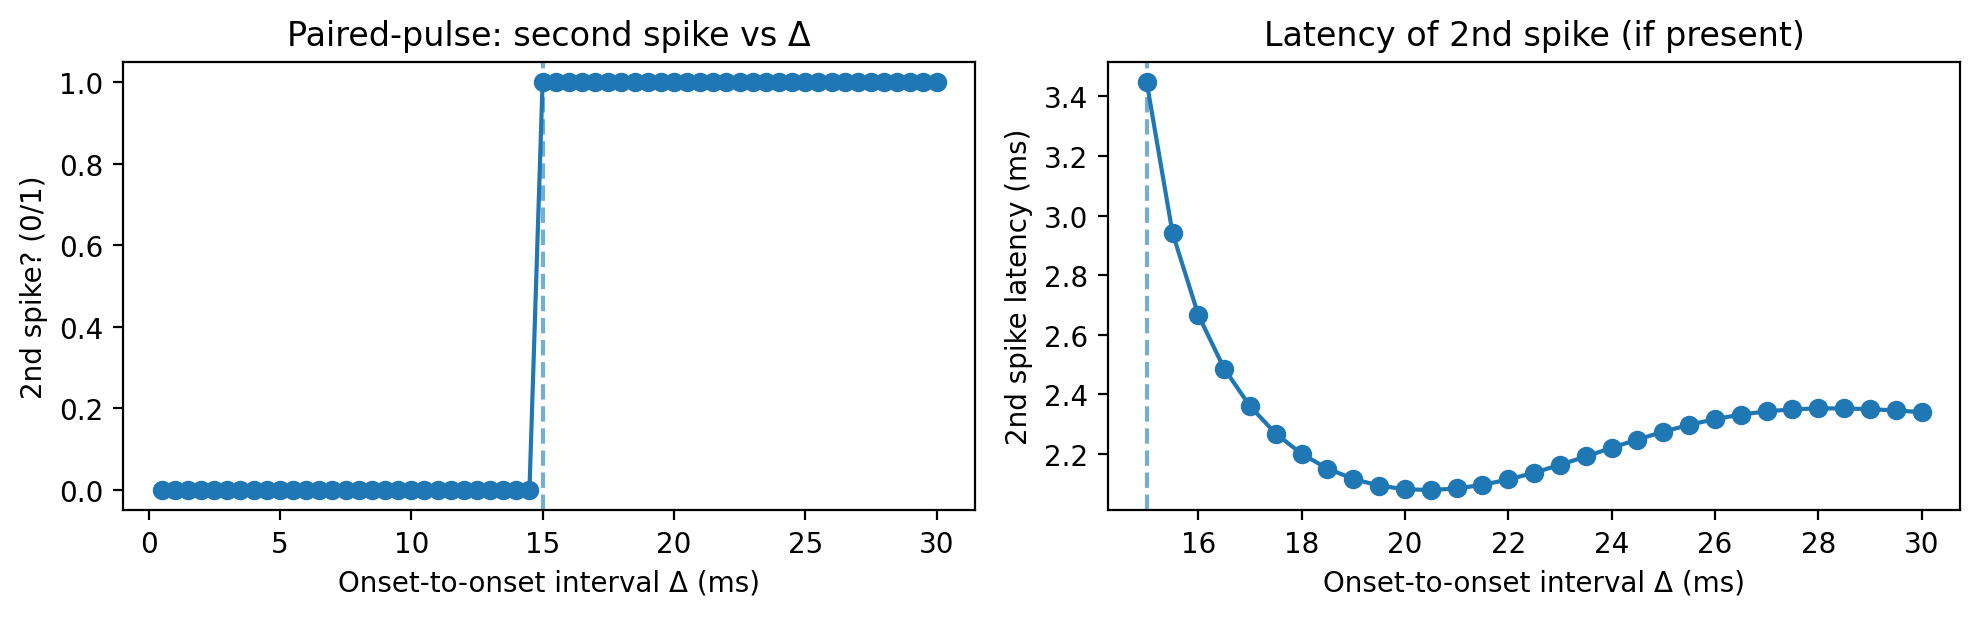

In [15]:
# refractory periods and paired pulses
# paired-pulse stimulus: two square pulses of width 'width' ms.
# 'delta_onset' is the onset-to-onset interval between the two pulses.

# stimulus: two square pulses, width=1 ms by default
def paired_pulse_current_factory(I1=10.0, I2=10.0, t1_on=10.0, width=1.0, delta_onset=5.0):
    """Return I_of_t(t) and the onset time of the second pulse t2_on."""
    t2_on = t1_on + delta_onset
    t1_off, t2_off = t1_on + width, t2_on + width
    def I_of_t(t):
        if t1_on <= t < t1_off: return I1
        if t2_on <= t < t2_off: return I2
        return 0.0
    return I_of_t, t2_on

# check onset-to-onset intervals and test if a 2nd spike occurs
deltas = np.arange(0.5, 30.5, 0.5)  # ms
has_second = np.zeros_like(deltas, dtype=int)
latency2   = np.full_like(deltas, np.nan, dtype=float) # latency of 2nd spike relative to 2nd pulse onset (ms); np.nan if none

# small epsilon so we consider spikes strictly after the 2nd onset
EPS = 1e-3  # ms
LAT_MAX = 12.0  # max latency window after 2nd onset to count as evoked by the 2nd pulse

for k, d in enumerate(deltas):
    I_of_t, t2_on = paired_pulse_current_factory(I1=10.0, I2=10.0, t1_on=10.0, width=1.0, delta_onset=d)
    T_end = t2_on + 40.0  # run a bit after the 2nd pulse
    res = simulate_hh(T=T_end, dt=0.01, V0=-65.0, I_of_t=I_of_t, p=params)

    # detect all spikes without imposing an artificial refractory
    spk = detect_spikes(res["t"], res["V"], thresh=0.0, refractory=0.0)

    # index of the first spike strictly after the 2nd onset
    idx_after2 = np.searchsorted(spk, t2_on + EPS, side="left")

    # count a "second spike" only if: there was at least one spike before the 2nd onset (idx_after2 >= 1), and
    # there is a spike after the 2nd onset
    if idx_after2 >= 1 and idx_after2 < spk.size:
        candidate = spk[idx_after2]
        if candidate <= t2_on + LAT_MAX:
            has_second[k] = 1
            latency2[k]   = candidate - t2_on
        # else: treat as no 2nd spike (too delayed to be attributed to the 2nd pulse)

# onset Δ* where a second spike first appears at 10 µA/cm²
if has_second.any():
    onset_idx = np.argmax(has_second == 1)
    delta_onset_star = deltas[onset_idx]
else:
    delta_onset_star = np.nan

print(f"Second-spike onset Δ* at 10 µA/cm² ≈ {delta_onset_star:.2f} ms")

# plots
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

axes[0].plot(deltas, has_second, marker="o")
axes[0].set_xlabel("Onset-to-onset interval Δ (ms)")
axes[0].set_ylabel("2nd spike? (0/1)")
axes[0].set_title("Paired-pulse: second spike vs Δ")
if np.isfinite(delta_onset_star):
    axes[0].axvline(delta_onset_star, ls="--", alpha=0.6)

axes[1].plot(deltas, latency2, marker="o")
axes[1].set_xlabel("Onset-to-onset interval Δ (ms)")
axes[1].set_ylabel("2nd spike latency (ms)")
axes[1].set_title("Latency of 2nd spike (if present)")
if np.isfinite(delta_onset_star):
    axes[1].axvline(delta_onset_star, ls="--", alpha=0.6)

plt.tight_layout()
plt.show()


In [16]:
# amplitude sweep to approximate absolute refractory: for each Δ, larger I2
I2_grid = np.linspace(10.0, 40.0, 7)
can_evoked = np.zeros_like(deltas, dtype=int)

for k, d in enumerate(deltas):
    for I2 in I2_grid:
        I_of_t, t2_on = paired_pulse_current_factory(I1=10.0, I2=I2, t1_on=10.0, width=1.0, delta_onset=d)
        T_end = t2_on + 40.0
        res = simulate_hh(T=T_end, dt=0.01, V0=-65.0, I_of_t=I_of_t, p=params)
        spk = detect_spikes(res["t"], res["V"], thresh=0.0, refractory=0.0)
        idx_after2 = np.searchsorted(spk, t2_on + EPS, side="left")
        if idx_after2 >= 1 and idx_after2 < spk.size and (spk[idx_after2] - t2_on) <= LAT_MAX:
            can_evoked[k] = 1
            break  # stop increasing I2 for this Δ

# absolute refractory estimate: largest Δ where can_evoked == 0
abs_ref_idx = np.argmax(can_evoked == 1)  # first Δ where evocation becomes possible
abs_ref_est = deltas[abs_ref_idx] if can_evoked.any() else np.nan
print(f"Approx. absolute refractory ≈ {abs_ref_est:.2f} ms (no I2 in {I2_grid.min()}–{I2_grid.max()} evoked earlier)")


Approx. absolute refractory ≈ 9.50 ms (no I2 in 10.0–40.0 evoked earlier)


Immediately after the first spike, ℎ is low (Na channels inactivated) and 𝑛 is high (K channels open). A second 10 µA·cm⁻², 1 ms pulse cannot overcome this until Δ is long enough for ℎ to recover and 𝑛 to decay.

Once a second spike becomes possible, more recovery leads to shorter latency: less “integration time” is needed to hit threshold.

### Strength and duration

We now move on to experiments with strength and duration.

We measure the minimum current needed to elicit at least one spike as a function of pulse width \(d\). For each \(d\), we deliver a single square pulse (onset at 10 ms) and use bisection to find the threshold amplitude $I_\text{th}(d)$. We then fit the Weiss–Lapicque model $I_\text{th}(d)=I_\text{rh}\Big(1+\frac{\tau_\text{ch}}{d}\Big)$
to estimate the S–D rheobase $I_\text{rh}$ (asymptotic current for long pulses) and the chronaxie $\tau_\text{ch}$ (the duration at which $I_\text{th}=2I_\text{rh}$.  
The S–D rheobase is defined by single-spike threshold and can differ from the DC (f–I) rheobase defined by sustained firing.


Rheobase (fit): 1.202 µA/cm²
Chronaxie (fit): 5.182 ms


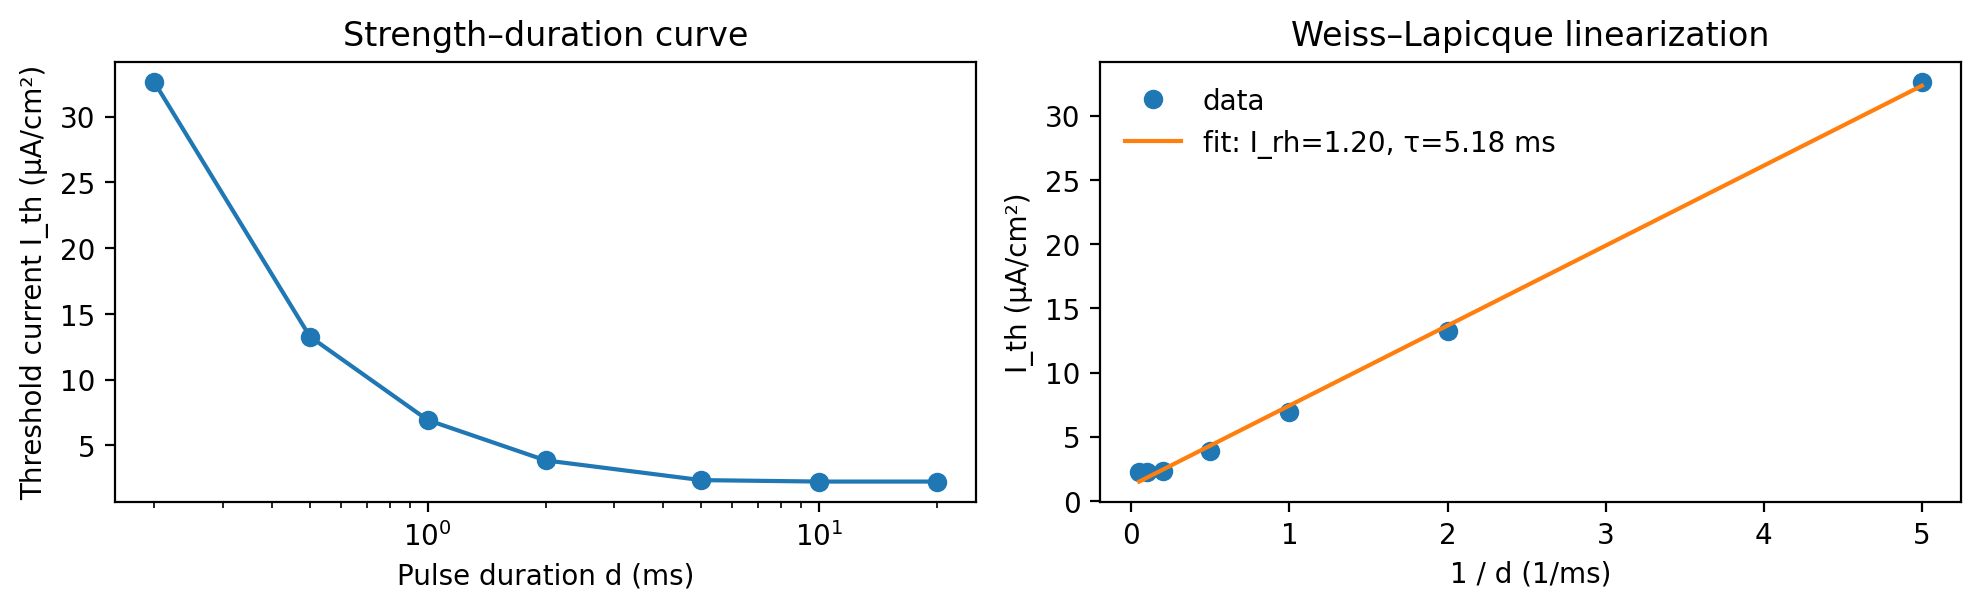

In [17]:
# strength–duration curve (threshold current vs pulse width)
# Weiss–Lapicque fit to estimate rheobase and chronaxie.

def spikes_from_pulse(I_amp, width_ms, t_on=10.0, V0=-65.0, dt=0.01):
    t_off = t_on + width_ms
    def I_of_t(t, amp=I_amp, on=t_on, off=t_off):
        return amp if (on <= t < off) else 0.0
    T = t_off + 40.0
    res = simulate_hh(T=T, dt=dt, V0=V0, I_of_t=I_of_t, p=params)
    spk = detect_spikes(res["t"], res["V"], thresh=0.0, refractory=2.0)
    # count spikes occurring after the pulse onset (0.5 ms slack)
    return np.sum(spk > t_on + 0.5)

def threshold_for_duration(width_ms, I_low=0.0, I_high=200.0, tol=0.05, max_iter=30):
    # bisection on current amplitude to find threshold for 1 spike
    lo, hi = I_low, I_high
    for _ in range(12):
        if spikes_from_pulse(hi, width_ms) >= 1: break
        hi *= 1.5
    if spikes_from_pulse(hi, width_ms) < 1:
        return np.nan
    # bisection
    for _ in range(max_iter):
        mid = 0.5*(lo+hi)
        s = spikes_from_pulse(mid, width_ms)
        if s >= 1:
            hi = mid
        else:
            lo = mid
        if (hi - lo) <= tol:
            break
    return hi

durations = np.array([0.2, 0.5, 1, 2, 5, 10, 20], float)
I_th = []
for d in durations:
    Ith = threshold_for_duration(d, I_low=0.0, I_high=50.0, tol=0.02)
    I_th.append(Ith)
I_th = np.array(I_th, float)

# Weiss–Lapicque
x = 1.0 / durations
y = I_th
# least-squares fit y = a + b*x  ⇒  a=I_rh, b=I_rh*tau_ch
X = np.vstack([np.ones_like(x), x]).T
coef, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
I_rh, b = coef
tau_ch = b / max(I_rh, 1e-9)

print(f"Rheobase (fit): {I_rh:.3f} µA/cm²")
print(f"Chronaxie (fit): {tau_ch:.3f} ms")

# plots
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

# I_th vs duration
axes[0].plot(durations, I_th, marker="o")
axes[0].set_xscale("log"); axes[0].set_xlabel("Pulse duration d (ms)")
axes[0].set_ylabel("Threshold current I_th (µA/cm²)")
axes[0].set_title("Strength–duration curve")

# I_th vs 1/d with fit
axes[1].plot(x, y, "o", label="data")
axes[1].plot(x, coef[0] + coef[1]*x, "-", label=f"fit: I_rh={I_rh:.2f}, τ={tau_ch:.2f} ms")
axes[1].set_xlabel("1 / d (1/ms)")
axes[1].set_ylabel("I_th (µA/cm²)")
axes[1].set_title("Weiss–Lapicque linearization")
axes[1].legend(frameon=False)

plt.tight_layout(); plt.show()

With brief stimulation, Na activation 𝑚 cannot rise enough and K activation 𝑛 + leak oppose depolarization; a larger current is required to reach threshold in the little time available.

𝜏≈5.2 ms is the characteristic integration/gating timescale: a 5.2 ms pulse needs exactly
2 $I_\text{rh}$.
Pulses much longer than 𝜏 behave quasi-step-like; pulses much shorter than 𝜏 must be disproportionately stronger.

This rheobase is for a single spike. It is much lower than the step rheobase for sustained firing (~6.25 µA/cm²). HH can generate one spike with a small long pulse, but repetitive spiking requires a much stronger steady drive.

Threshold current decreases with pulse width and follows
$$
I_{\mathrm{th}}(d) \approx I_{\mathrm{rh}}\!\left(1+\frac{\tau}{d}\right)
\qquad
I_{\mathrm{rh}} \approx 1.20~\mu\mathrm{A}\,\mathrm{cm}^{-2}\quad
\tau \approx 5.18~\mathrm{ms}
$$

This captures the neuron's temporal integration: short pulses need more current, while long pulses approach a low asymptotic threshold.


### Voltage clamps

Next, we have experiments with voltage clamps. It consists of clampimpg the membrane to a fixed waveform to isolate ionic currents and verify HH channel kinetics.

Unlike current clamp, here we prescribe the membrane voltage \(V(t)\) and integrate only the gates \(m,h,n\). We apply a step from a holding potential (–65 mV) to 0 mV (10–30 ms) and compute the resulting currents:

$$
I_\mathrm{Na}=\bar g_\mathrm{Na} m^3 h (V-E_\mathrm{Na})\quad
I_\mathrm{K}=\bar g_\mathrm{K} n^4 (V-E_\mathrm{K})\quad
I_\mathrm{L}=g_\mathrm{L}(V-E_\mathrm{L})
$$

At 0 mV, $I_\mathrm{Na}$ is inward (negative) and transient; $I_\mathrm{K}$ is outward (positive) and delayed. We repeat the step under TTX $(g_\mathrm{Na}=0)$ and TEA $(g_\mathrm{K}=0)$ to isolate each component.


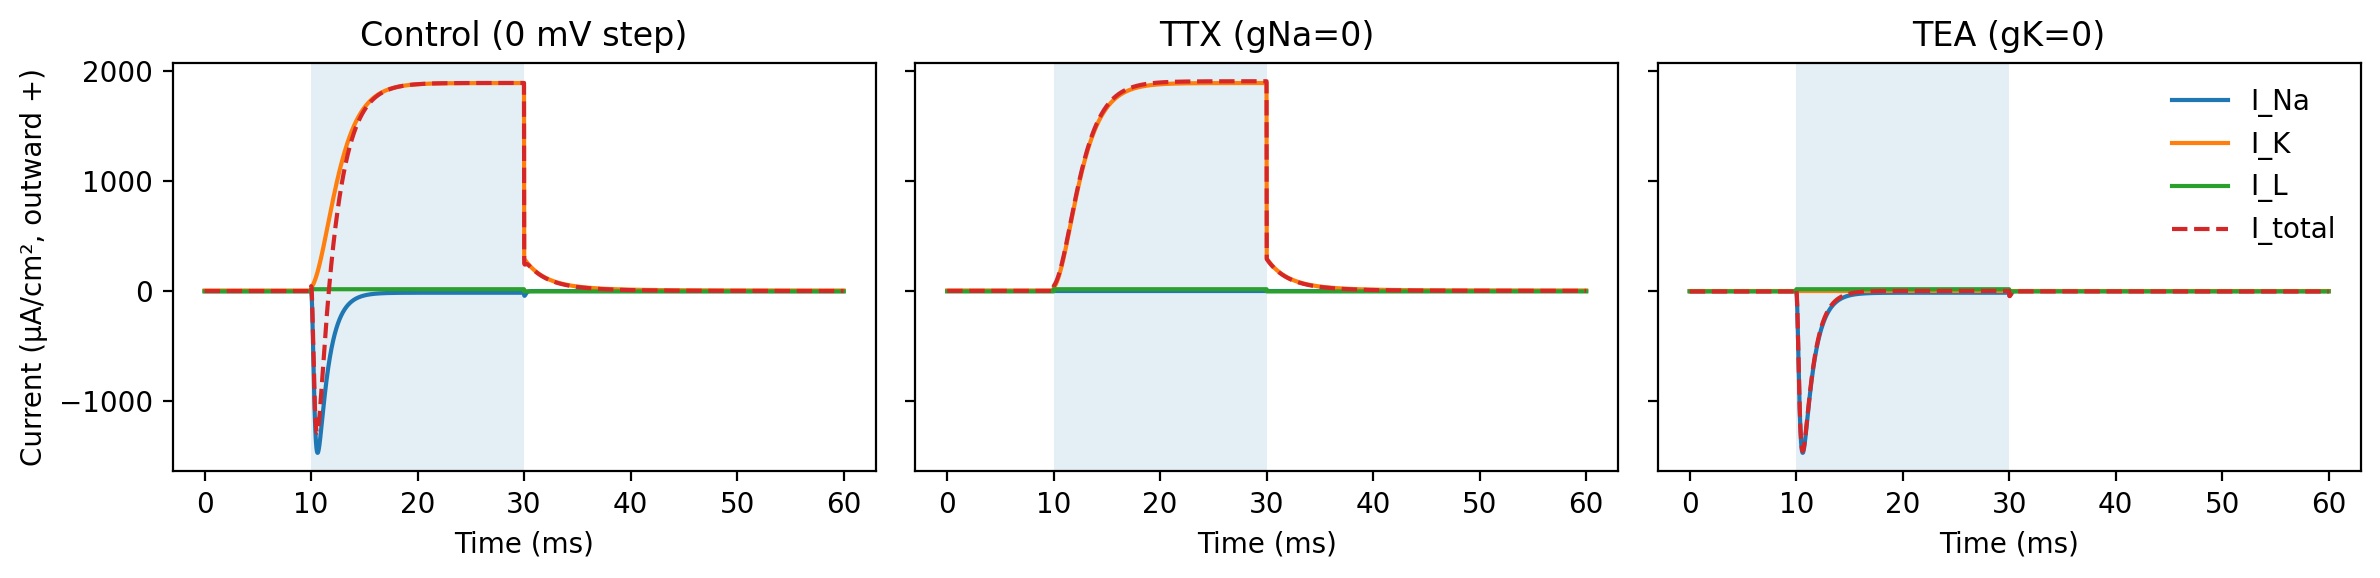

In [18]:
def simulate_vclamp(T=60.0, dt=0.01, V_of_t=lambda t: -65.0, p=params, V0=None):
    # integrate gates under prescribed V(t), returns dict with t,V,m,h,n and currents
    steps = int(np.round(T/dt)) + 1
    t = np.arange(steps) * dt
    V = np.array([V_of_t(tt) for tt in t], dtype=float)

    # init gates at steady state for starting voltage
    V_init = V0 if V0 is not None else V[0]
    x_inf0, _ = gate_inf_tau(V_init, p)
    m = np.empty(steps); h = np.empty(steps); n = np.empty(steps)
    m[0] = float(x_inf0["m"]); h[0] = float(x_inf0["h"]); n[0] = float(x_inf0["n"])

    INa = np.empty(steps); IK = np.empty(steps); IL = np.empty(steps)

    # currents at t=0
    INa[0], IK[0], IL[0] = ionic_currents(V[0], m[0], h[0], n[0], p)

    for k in range(steps-1):
        # update gates (relaxation form at clamped V)
        x_inf, tau = gate_inf_tau(V[k], p)
        dm = (x_inf["m"] - m[k]) / tau["m"]
        dh = (x_inf["h"] - h[k]) / tau["h"]
        dn = (x_inf["n"] - n[k]) / tau["n"]
        m[k+1] = np.clip(m[k] + dt*dm, 0.0, 1.0)
        h[k+1] = np.clip(h[k] + dt*dh, 0.0, 1.0)
        n[k+1] = np.clip(n[k] + dt*dn, 0.0, 1.0)

        INa[k+1], IK[k+1], IL[k+1] = ionic_currents(V[k+1], m[k+1], h[k+1], n[k+1], p)

    return {"t": t, "V": V, "m": m, "h": h, "n": n, "INa": INa, "IK": IK, "IL": IL}

# step protocols
def V_step_voltage(t, V_hold=-65.0, V_target=0.0, t_on=10.0, t_off=30.0):
    return V_target if (t_on <= t < t_off) else V_hold

# control, TTX (gNa=0), TEA (gK=0) at a 0 mV step
res_ctl = simulate_vclamp(T=60.0, dt=0.01, V_of_t=lambda tt: V_step_voltage(tt, V_hold=-65, V_target=0, t_on=10, t_off=30), p=params)
res_ttx = simulate_vclamp(T=60.0, dt=0.01, V_of_t=lambda tt: V_step_voltage(tt, V_hold=-65, V_target=0, t_on=10, t_off=30),
                          p=replace(params, gNa=0.0))
res_tea = simulate_vclamp(T=60.0, dt=0.01, V_of_t=lambda tt: V_step_voltage(tt, V_hold=-65, V_target=0, t_on=10, t_off=30),
                          p=replace(params, gK=0.0))

# plot currents: outward is positive; Na inward (negative) at 0 mV is expected
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True)
for ax, res, title in zip(
    axes,
    (res_ctl, res_ttx, res_tea),
    ("Control (0 mV step)", "TTX (gNa=0)", "TEA (gK=0)")
):
    t = res["t"]; V = res["V"]
    INa, IK, IL = res["INa"], res["IK"], res["IL"]
    Itot = INa + IK + IL
    ax.plot(t, INa, label="I_Na")
    ax.plot(t, IK,  label="I_K")
    ax.plot(t, IL,  label="I_L")
    ax.plot(t, Itot, label="I_total", linestyle="--")
    ax.axvspan(10, 30, alpha=0.12)
    ax.set_title(title)
    ax.set_xlabel("Time (ms)")
axes[0].set_ylabel("Current (µA/cm², outward +)")
axes[-1].legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()


Control:  at step onset, \(V - $E_{\mathrm{Na}} < 0$, so $I_{\mathrm{Na}}$ is a large inward (negative) transient — \(m\) opens rapidly, then \(h\) inactivates, driving the decay. In parallel, $V - E_{\mathrm{K}} > 0$, so $I_{\mathrm{K}}$ rises outward (positive) with a delay as \(n\) activates slowly; it reaches a near-plateau during the step. Leak is small and outward at $0~\mathrm{mV}$. The total current shows a brief inward dip then a dominant outward level. On step-off, there is an outward tail as \(n\) deactivates back toward rest.

TTX: $g_{\mathrm{Na}} = 0$: the inward Na transient disappears; what remains is the delayed outward K current plus leak. The outward tail after step-off cleanly reveals K deactivation dynamics.

TEA: $g_{\mathrm{K}} = 0$: the delayed outward component vanishes; only the fast inward Na transient (and tiny leak) is visible. The current decays toward zero during the step as \(h\) inactivates, and there is little tail on step-off.


### Steady-state I-V curve

Then experiments with a steady-state I-V curve.

For each voltage \(V\) we set $(m=h=n=x_\infty(V))$ and compute
$$
I_{\mathrm{Na}}(V)=\bar g_{\mathrm{Na}}\ m_\infty^3(V)h_\infty(V) V-E_{\mathrm{Na}}] \quad
$$

$$
I_{\mathrm{K}}(V)=\bar g_{\mathrm{K}}\ n_\infty^4(V)\ [V-E_{\mathrm{K}}]\quad
$$

$$
I_{\mathrm{L}}(V)=g_{\mathrm{L}}\,[V-E_{\mathrm{L}}]
I_{\mathrm{tot}}(V)=I_{\mathrm{Na}}(V)+I_{\mathrm{K}}(V)+I_{\mathrm{L}}(V)
$$
with outward current plotted positive.

The total current $I_\text{total}(V)$ shows how ionic currents balance at each voltage. The zero crossing $I_\text{total}=0$ estimates the resting potential (with $I_\text{ext}=0)$.

(Q10 does not affect this curve because it changes $\tau_x$, not $x_\infty$).


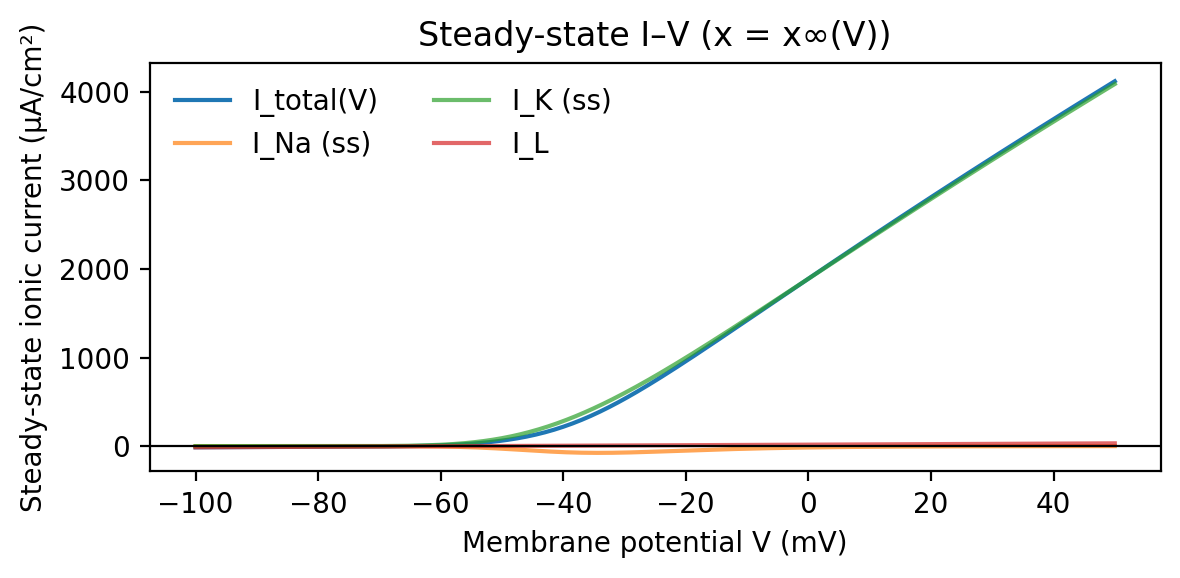

Estimated resting potential from I–V zero crossing: -65.00 mV


In [19]:
# steady-state I–V: total ionic current at x = x_inf(V)
Vs = np.linspace(-100, 50, 301)
Itot = []
INa_ss = []; IK_ss = []; IL_ss = []
for V in Vs:
    x_inf, _ = gate_inf_tau(V, params)
    m = float(x_inf["m"]); h = float(x_inf["h"]); n = float(x_inf["n"])
    INa, IK, IL = ionic_currents(V, m, h, n, params)
    INa_ss.append(INa); IK_ss.append(IK); IL_ss.append(IL)
    Itot.append(INa + IK + IL)
Itot = np.array(Itot); INa_ss = np.array(INa_ss); IK_ss = np.array(IK_ss); IL_ss = np.array(IL_ss)

plt.figure(figsize=(6,3))
plt.plot(Vs, Itot, label="I_total(V)")
plt.plot(Vs, INa_ss, label="I_Na (ss)", alpha=0.7)
plt.plot(Vs, IK_ss, label="I_K (ss)",  alpha=0.7)
plt.plot(Vs, IL_ss, label="I_L",       alpha=0.7)
plt.axhline(0, color="k", linewidth=0.8)
plt.xlabel("Membrane potential V (mV)")
plt.ylabel("Steady-state ionic current (µA/cm²)")
plt.title("Steady-state I–V (x = x∞(V))")
plt.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

# resting potential estimate = where I_total crosses 0
sign = np.sign(Itot)
z = np.where(sign[:-1]*sign[1:] < 0)[0]
if z.size > 0:
    i = z[0]
    # linear interp
    V_rest = Vs[i] + (0 - Itot[i]) * (Vs[i+1]-Vs[i]) / (Itot[i+1]-Itot[i])
    print(f"Estimated resting potential from I–V zero crossing: {V_rest:.2f} mV")
else:
    print("No zero crossing found in the scanned range.")


- The zero crossing of $I_{\mathrm{tot}}$ occurs at $V^*\approx -65~\mathrm{mV}$, so $I_{\mathrm{tot}}(V^*)=0$; this predicts the resting potential for $I_{\text{ext}}=0$.  
The local slope is positive, $ \left.\frac{d I_{\mathrm{tot}}}{dV}\right|_{V^*} > 0 $, implying a stable fixed point (small depolarizations evoke outward current; small hyperpolarizations evoke inward current).

- For $V\approx -65~\mathrm{mV}$: $I_{\mathrm{K}}>0$ (outward, since $V-E_{\mathrm{K}}>0$), $I_{\mathrm{L}}<0$ (inward, since $V<E_{\mathrm{L}}$), and $I_{\mathrm{Na}}<0$ (but small because $m_\infty$ is tiny and $h_\infty$ is moderate).  
As \(V\) increases above $-60~\mathrm{mV}$, $n_\infty(V)$ rises and $I_{\mathrm{K}}$ dominates, giving the strong outward growth of $I_{\mathrm{tot}}$.  
$I_{\mathrm{Na}}$ remains small at steady state for depolarized \(V\) because $h_\infty(V)$ is low (inactivation), explaining why Na current is transient under steps.

- The predicted $V^*$ matches the initialized/resting voltage and the post-spike return in current clamp; the dominance of $I_{\mathrm{K}}$ at depolarized \(V\) aligns with the delayed outward current seen under voltage clamp.


### Current clamp, pharmacology demo

The next experiment is a current-clamp pharmacology demo.

We inject the same depolarizing step (10–110 ms) under three conditions: Control, TTX $(g_\mathrm{Na}=0)$ blocking fast $Na^+$, and TEA $(g_\mathrm{K}=0)$ blocking delayed rectifier $K^+$. This reveals how each channel family shapes spiking under current clamp.


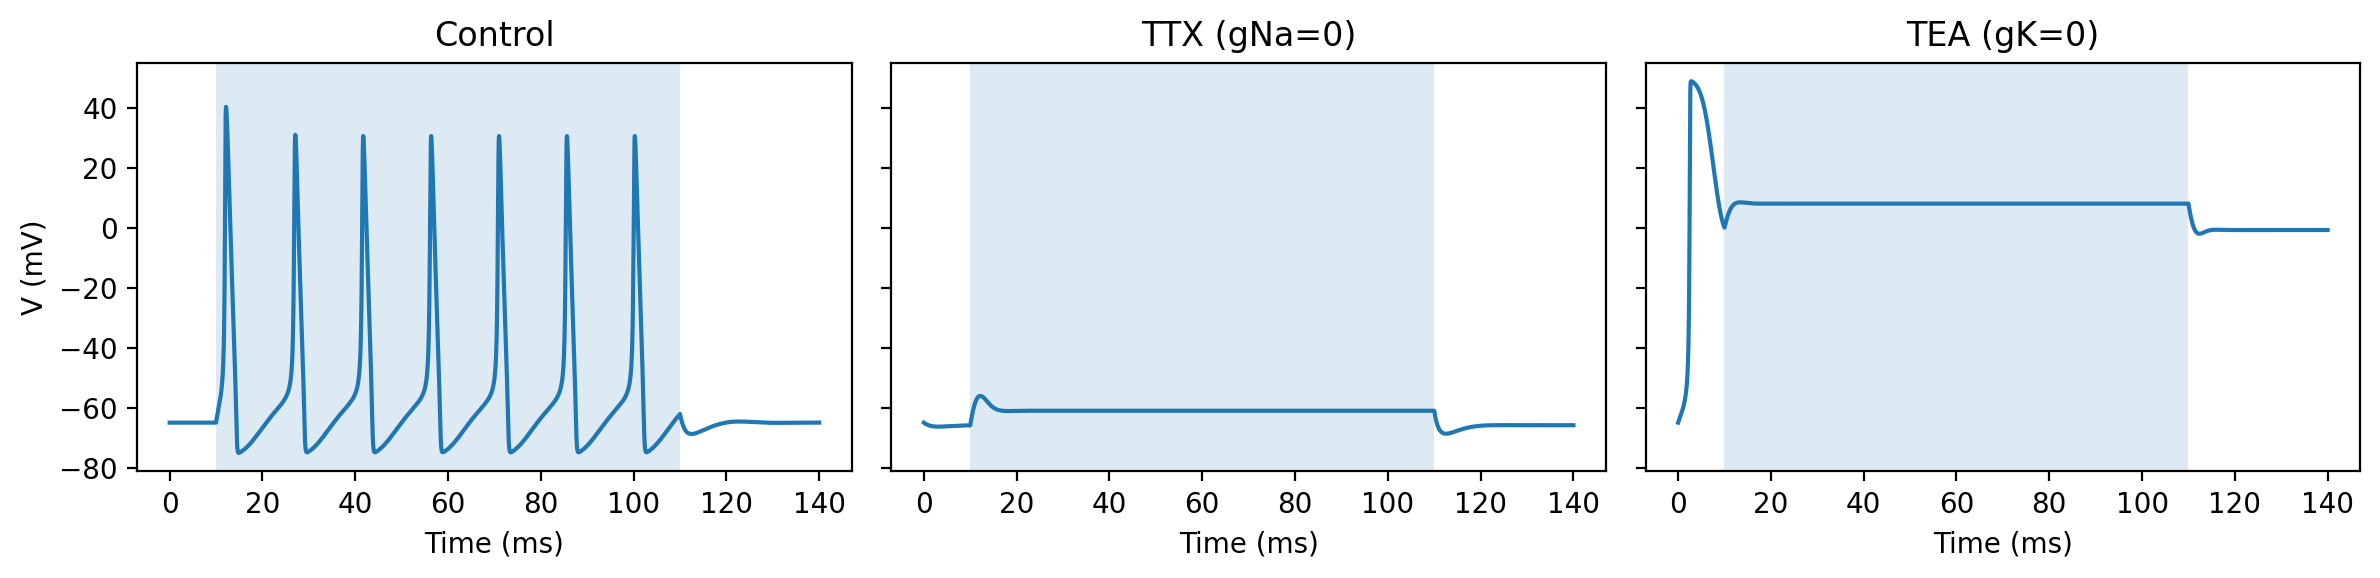

In [20]:
# current clamp with channel blocks (TTX: gNa=0, TEA: gK=0)
def run_step(I=10.0, t_on=10.0, t_off=110.0, p=params):
    return simulate_hh(
        T=t_off+30.0, dt=0.01, V0=-65.0,
        I_of_t=lambda t, I=I, on=t_on, off=t_off: (I if (on <= t < off) else 0.0),
        p=p
    )

# control
res_ctl = run_step(I=10.0, t_on=10.0, t_off=110.0, p=params)

# TTX: block Na (gNa=0)
res_ttx = run_step(I=10.0, t_on=10.0, t_off=110.0, p=replace(params, gNa=0.0))

# TEA: block K (gK=0)
res_tea = run_step(I=10.0, t_on=10.0, t_off=110.0, p=replace(params, gK=0.0))

# plot
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True)

for ax, res, title in zip(
    axes,
    (res_ctl, res_ttx, res_tea),
    ("Control", "TTX (gNa=0)", "TEA (gK=0)")
):
    t, V = res["t"], res["V"]
    ax.plot(t, V)
    ax.axvspan(10, 110, alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel("Time (ms)")
axes[0].set_ylabel("V (mV)")
plt.tight_layout(); plt.show()


Na current is necessary for spike initiation (fast upstroke). Blocking it (TTX) abolishes spiking entirely.

K current is necessary for repolarization and for resetting excitability between spikes. Blocking it (TEA) removes the outward drive needed to end each spike, so the neuron enters depolarization block after the first AP.

These behaviors mirror the voltage-clamp results: a fast transient Na current at onset and a delayed, sustained K current that dominates during prolonged depolarization.

### Temperature scaling

Finally, we look at experiments involving temperature scaling.

A generic kinetic rate \(k\) speeds up with temperature according to the Q10 law:
$$
k\!\left(T_{\mathrm{exp}}\right)
= k\!\left(T_{\mathrm{ref}}\right)\;
Q_{10}^{\frac{T_{\mathrm{exp}}-T_{\mathrm{ref}}}{10}}
$$

Scaling factor:
$$
S \;=\; Q_{10}^{\frac{T_{\mathrm{exp}}-T_{\mathrm{ref}}}{10}}
$$

All gating rates are multiplied by the same factor \(S\):
$$
\alpha_x^{\ast}(V) \;=\; S\,\alpha_x(V), \qquad
\beta_x^{\ast}(V) \;=\; S\,\beta_x(V), \qquad x \in \{m,h,n\}.
$$

The steady state is unchanged, but the time constants shrink:
$$
x_\infty(V) \;=\; \frac{\alpha_x}{\alpha_x+\beta_x}
\;\;\Rightarrow\;\;
x_\infty^{\ast}(V) \;=\; \frac{S\alpha_x}{S(\alpha_x+\beta_x)} \;=\; x_\infty(V),
$$
$$
\tau_x(V) \;=\; \frac{1}{\alpha_x+\beta_x}
\;\;\Rightarrow\;\;
\tau_x^{\ast}(V) \;=\; \frac{1}{S(\alpha_x+\beta_x)} \;=\; \frac{\tau_x(V)}{S}.
$$

What this actually means in practice is that, at higher \(T\), the gates chase their targets faster (smaller $\tau_x$), but the targets $x_\infty(V)$ themselves do not move.


- $x_\infty(V)$: no change between temperatures.
- $\tau_m(V)$, $\tau_h(V)$, $\tau_n(V)$: all drop by roughly the same factor \(S\).
- Single-spike overlay: narrower spike, shorter latency, often higher firing rate for the same current.

Q10 scaling: Q10=3.00, T_ref=6.3°C, T_exp=20.0°C  →  rate× = 4.50
Note: x_inf(V) unchanged; tau_x(V) scaled by 1/S (gates move faster at higher T).


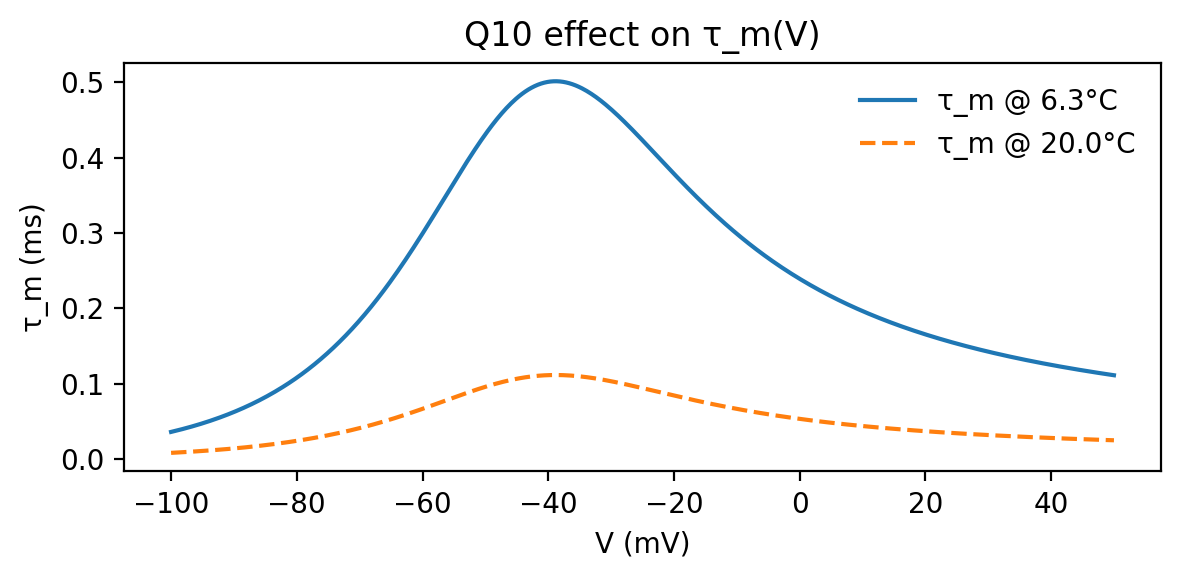

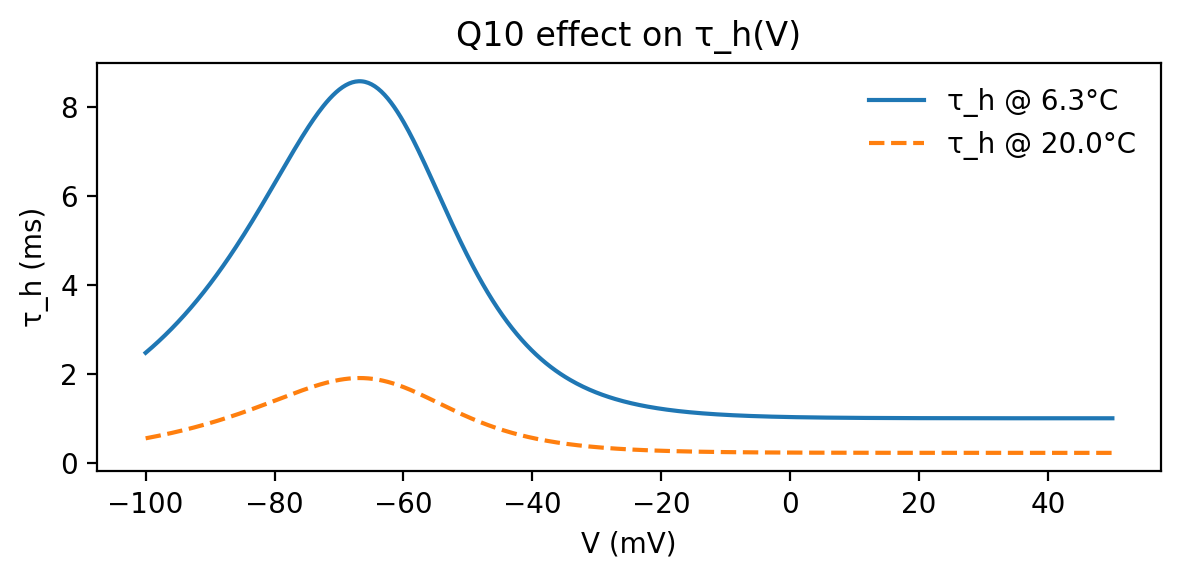

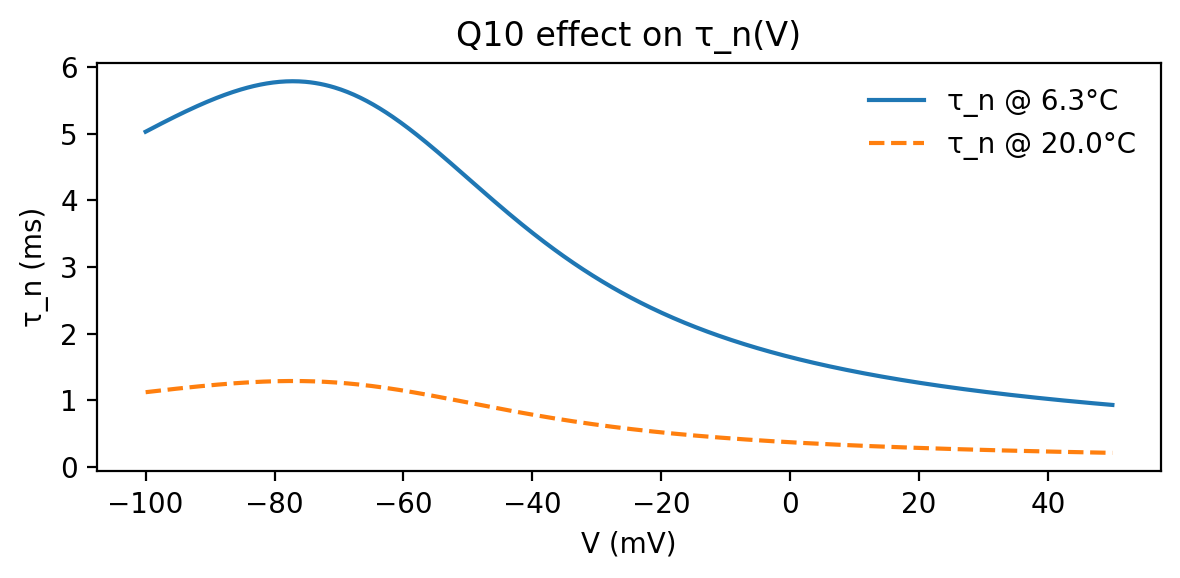

max |Δ m∞| = 2.220446049250313e-16  max |Δ h∞| = 2.220446049250313e-16  max |Δ n∞| = 2.220446049250313e-16


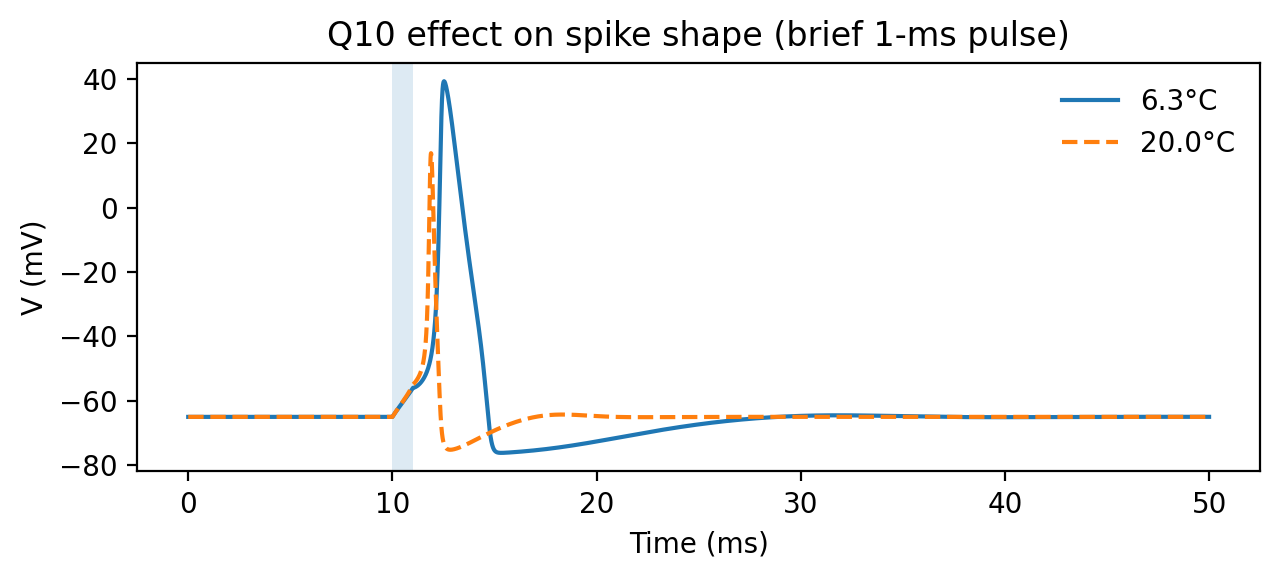

6.3°C: peak 39.3 mV at 12.53 ms, half-width ≈ 1.443 ms
20.0°C: peak 17.0 mV at 11.89 ms, half-width ≈ 0.365 ms


In [21]:
# Q10 demo
# classic HH at ~6.3°C vs. a warmer bath
# x_inf(V) unchanged; tau_x(V) shrink -> faster gates, narrower spikes, higher rate

T_ref = 6.3   # classic squid axon reference (°C)
T_warm = 20.0 # 20°C

# --- two parameter sets ---
p_ref  = replace(params, use_Q10=False, T_ref=T_ref, T_exp=T_ref)  # no scaling
p_warm = replace(params, use_Q10=True,  T_ref=T_ref, T_exp=T_warm) # Q10 on (Q10 already in params)

# scaling factor S
S = (p_warm.Q10 ** ((p_warm.T_exp - p_warm.T_ref)/10.0)) if p_warm.use_Q10 else 1.0
print(f"Q10 scaling: Q10={p_warm.Q10:.2f}, T_ref={T_ref:.1f}°C, T_exp={T_warm:.1f}°C  →  rate× = {S:.2f}")
print("Note: x_inf(V) unchanged; tau_x(V) scaled by 1/S (gates move faster at higher T).")

# τ_x(V): overlay (ref vs warm) ---
Vgrid = np.linspace(-100, 50, 600)
_, tau_ref  = gate_inf_tau(Vgrid, p_ref)
_, tau_warm = gate_inf_tau(Vgrid, p_warm)

# τ_m(V)
plt.figure(figsize=(6,3))
plt.plot(Vgrid, tau_ref["m"], label=f"τ_m @ {T_ref:.1f}°C")
plt.plot(Vgrid, tau_warm["m"], linestyle="--", label=f"τ_m @ {T_warm:.1f}°C")
plt.xlabel("V (mV)"); plt.ylabel("τ_m (ms)"); plt.title("Q10 effect on τ_m(V)")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

# τ_h(V)
plt.figure(figsize=(6,3))
plt.plot(Vgrid, tau_ref["h"], label=f"τ_h @ {T_ref:.1f}°C")
plt.plot(Vgrid, tau_warm["h"], linestyle="--", label=f"τ_h @ {T_warm:.1f}°C")
plt.xlabel("V (mV)"); plt.ylabel("τ_h (ms)"); plt.title("Q10 effect on τ_h(V)")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

# τ_n(V)
plt.figure(figsize=(6,3))
plt.plot(Vgrid, tau_ref["n"], label=f"τ_n @ {T_ref:.1f}°C")
plt.plot(Vgrid, tau_warm["n"], linestyle="--", label=f"τ_n @ {T_warm:.1f}°C")
plt.xlabel("V (mV)"); plt.ylabel("τ_n (ms)"); plt.title("Q10 effect on τ_n(V)")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

# sanity check to verify x_inf is unchanged
x_ref, _ = gate_inf_tau(Vgrid, p_ref)
x_wrm, _ = gate_inf_tau(Vgrid, p_warm)
print("max |Δ m∞| =", float(np.max(np.abs(x_ref["m"]-x_wrm["m"]))),
      " max |Δ h∞| =", float(np.max(np.abs(x_ref["h"]-x_wrm["h"]))),
      " max |Δ n∞| =", float(np.max(np.abs(x_ref["n"]-x_wrm["n"]))))

# single-spike overlay (brief 1-ms, 10 µA/cm² pulse)
stim_pulse = lambda t: (10.0 if (10.0 <= t < 11.0) else 0.0)

res_ref  = simulate_hh(T=50.0, dt=0.01, V0=-65.0, I_of_t=stim_pulse, p=p_ref)
res_warm = simulate_hh(T=50.0, dt=0.01, V0=-65.0, I_of_t=stim_pulse, p=p_warm)

# plot the results
plt.figure(figsize=(6.5,3))
plt.plot(res_ref["t"],  res_ref["V"],  label=f"{T_ref:.1f}°C")
plt.plot(res_warm["t"], res_warm["V"], linestyle="--", label=f"{T_warm:.1f}°C")
plt.axvspan(10, 11, alpha=0.15)
plt.xlabel("Time (ms)"); plt.ylabel("V (mV)")
plt.title("Q10 effect on spike shape (brief 1-ms pulse)")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

# metrics
for label, res in [(f"{T_ref:.1f}°C", res_ref), (f"{T_warm:.1f}°C", res_warm)]:
    t, V = res["t"], res["V"]
    base = float(np.mean(V[(t>=5)&(t<10)]))
    i_pk = int(np.argmax(V))
    hw = half_width(t, V, i_pk, base)
    print(f"{label}: peak {V[i_pk]:.1f} mV at {t[i_pk]:.2f} ms, half-width ≈ {hw:.3f} ms")


Raising \(T\) speeds the gates (same $x_\infty$, shorter $\tau_x$, producing earlier, narrower, lower-amplitude spikes and faster repetitive firing for the same input.


## ANALYSIS — Phase plane (V–n) with nullclines

Assuming the fast gates follow $m\approx m_\infty(V)$, $h\approx h_\infty(V)$, the Hodgkin-Huxley dynamics can be visualized in the \(V, n) plane. We plot the nullclines:
- $dV/dt=0$: points where the net ionic current balances the external current (here $I_\text{ext}=0)$, giving \(n(V)\).
- $dn/dt=0$: \(n=$n_\infty(V)$.

Their intersection is the fixed point (rest). A brief current pulse (10–11 ms) is simulated with the full model and overlaid as a trajectory (V(t), n(t)).

Q10 rescales time constants but does not shift these nullclines.


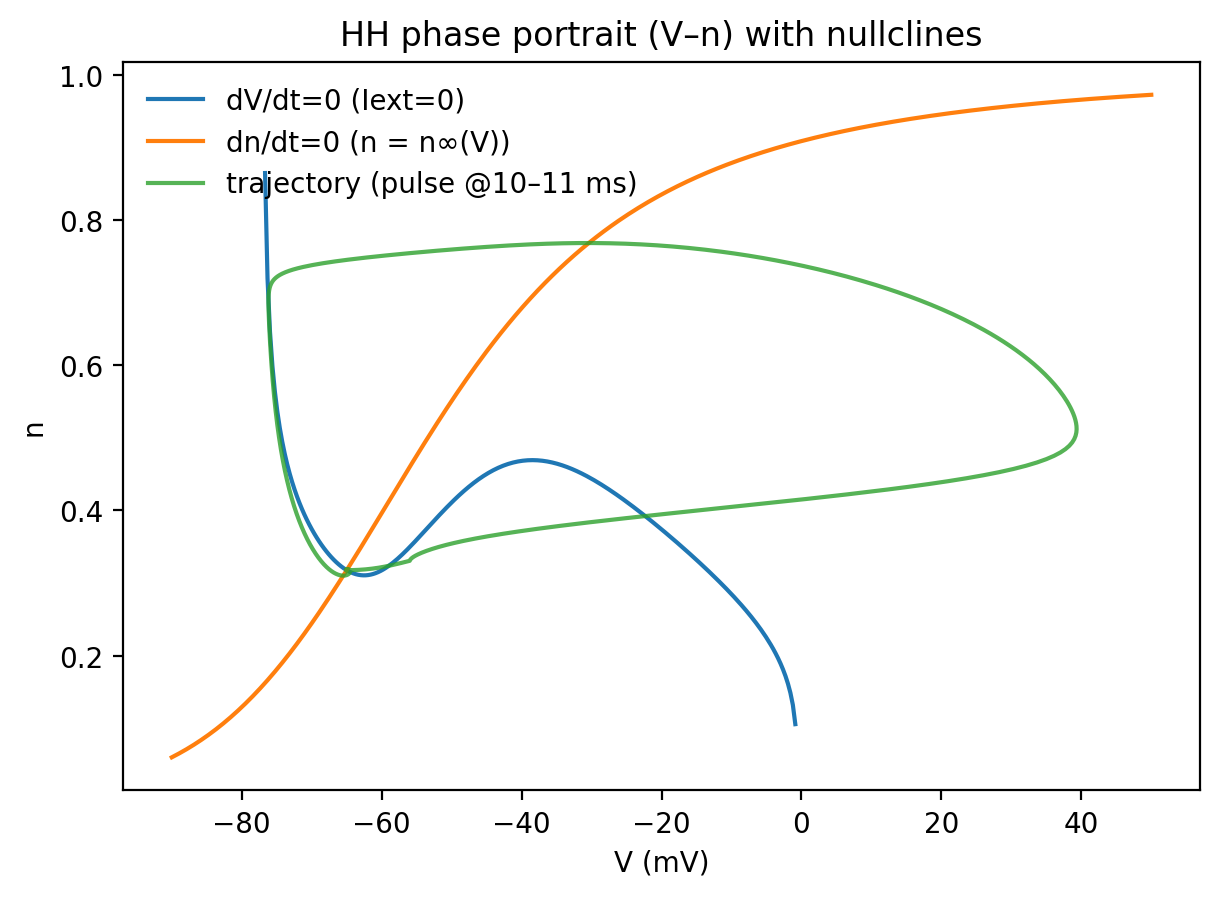

In [22]:
# V–n phase portrait with nullclines (m,h fast; n slow)

def total_ionic_current(V, n, p=params):
    # m,h at steady state for this V
    x_inf, _ = gate_inf_tau(V, p)
    m, h = float(x_inf["m"]), float(x_inf["h"])
    INa = p.gNa * (m**3) * h * (V - p.ENa)
    IK  = p.gK  * (n**4)     * (V - p.EK)
    IL  = p.gL              * (V - p.EL)
    return INa + IK + IL

def V_nullcline(Iext=0.0, Vs=np.linspace(-90, 50, 400), p=params):
    # dV/dt=0 for n(V): Iext - (INa+IK+IL) = 0  -> IK term isolates n^4
    n_vals = np.full_like(Vs, np.nan, dtype=float)
    for i, V in enumerate(Vs):
        x_inf, _ = gate_inf_tau(V, p)
        m, h = float(x_inf["m"]), float(x_inf["h"])
        # A(V) = Iext - INa - IL; B(V) = gK*(V - EK); need n^4 = A/B
        A = Iext - (p.gNa*(m**3)*h*(V - p.ENa) + p.gL*(V - p.EL))
        B = p.gK * (V - p.EK)
        if B != 0.0:
            r = A / B
            if r >= 0.0:
                n = r**0.25
                if 0.0 <= n <= 1.0:
                    n_vals[i] = n
    return Vs, n_vals

def n_nullcline(Vs=np.linspace(-90, 50, 400), p=params):
    # n = n_inf(V)
    x_inf, _ = gate_inf_tau(Vs, p)
    return Vs, np.asarray(x_inf["n"], float)

# nullclines for Iext = 0 (resting slice)
Vs = np.linspace(-90, 50, 400)
Vn_V, Vn_n = V_nullcline(Iext=0.0, Vs=Vs, p=params)
Nn_V, Nn_n = n_nullcline(Vs=Vs, p=params)

# simulate a trajectory with a brief pulse, then free evolution (for the path)
res = simulate_hh(
    T=60.0, dt=0.01, V0=-65.0,
    I_of_t=lambda t: (10.0 if (10.0 <= t < 11.0) else 0.0),  # brief pulse
    p=params
)
# n(t) and V(t)
V_tr, n_tr = res["V"], res["n"]

# plot phase portrait
plt.figure(figsize=(6.2, 4.6))
# nullclines
plt.plot(Vn_V[np.isfinite(Vn_n)], Vn_n[np.isfinite(Vn_n)], label="dV/dt=0 (Iext=0)")
plt.plot(Nn_V, Nn_n, label="dn/dt=0 (n = n∞(V))")
# trajectory
plt.plot(V_tr, n_tr, alpha=0.8, label="trajectory (pulse @10–11 ms)")
plt.xlabel("V (mV)"); plt.ylabel("n")
plt.title("HH phase portrait (V–n) with nullclines")
plt.legend(frameon=False)
plt.tight_layout(); plt.show()


  - Blue: $\dot V = 0$ (V-nullcline) for $I_{\text{ext}} = 0$; i.e., where $I_{\mathrm{Na}} + I_{\mathrm{K}} + I_{\mathrm{L}} = 0$.
  - Orange: $\dot n = 0$ (n-nullcline), given by $n = n_\infty(V)$.
  - Their intersection (around V $\approx -65\,\mathrm{mV}$ is the resting fixed point.

Near the intersection, small right/left deviations in \(V\) are opposed by net outward/inward current, and \(n\) relaxes toward $n_\infty(V)$; the fixed point is stable.

Trajectory (green) for a brief pulse, 10–11 ms: upstroke: (\(n\) is slow, so the state moves mainly rightward (large \($\Delta V$\), little change in \(n\))); peak and repolarization (at high \(V\), \(n\) increases (moves up); larger $\mathrm{K}^+$ conductance then drives \(V\) leftward back toward negative potentials); recovery (with \(V\) near rest but \(n\) still elevated, the path goes downward as n to $n_\infty(V)$, returning to the fixed point).


The nullclines locate a stable rest; the pulse propels the system past the V-nullcline knee, producing a clockwise spike excursion (right → up → left → down) that returns to rest as the slow variable 𝑛 relaxes — illustrating fast 𝑉 vs slow 𝑛 dynamics of the Hodgkin-Huxley neuron.

## CONCLUSION

This project consisted of a single-compartment, conductance-based Hodgkin–Huxley neuron with Na⁺ activation/inactivation (m,h) and K⁺ activation (n), simulated via Euler integration with small ∆t and limit-safe gating rates.

Key observations:
- Spike mechanism: fast $m\uparrow$ drives the upstroke; $h\downarrow$ terminates Na⁺ current; slower $n\uparrow$ repolarizes and sets refractoriness.
- f–I: clear rheobase; near the threshold the classic parameterization typically shows a finite onset frequency.
- Refractoriness: paired-pulse tests reveal absolute and relative refractory periods from \(h, n\) recovery.
- Strength–duration: the threshold current decreases with pulse width; Weiss–Lapicque fit yields rheobase $I_{rh}$ and chronaxie $\tau_c$.
- Voltage clamp: transient inward (Na⁺) followed by sustained outward (K⁺) with total current crossing over in time.
- Pharmacology/Q10: blocking Na⁺ abolishes spiking; blocking K⁺ broadens spikes; warming (Q10) speeds gating and narrows spikes.

Limitations: single compartment, deterministic channels, no synaptic dynamics or morphology. Euler is fine here but stiff/fast regimes may benefit from smaller ∆t or higher-order solvers.